# Alerta de "lista frágil" en la postulación PAES
## Informe Técnico — Módulo 3: Machine Learning para la Toma de Decisiones
**Diplomado en Ciencia de Datos Aplicada · UTFSM · Proyecto Capstone "Quedar fuera teniendo puntaje"**

**Autores:** Daniela y Emanuel Nicklichen *(completar nombres completos antes de entregar)*  ·  **Fecha:** noviembre de 2026

> **Cómo leer este notebook.** Responde las cuatro preguntas de la pauta: **¿Qué se propone?** (sección 1), **¿Cómo se implementa?** (secciones 2 y 4), **¿Cómo se valida?** (secciones 3, 5 y 6) y **¿Está bien hecho?** (secciones 7 a 12). Cada resultado que luego aparece en el *Análisis de la Solución* (PDF de 3 páginas) sale de una celda de este notebook y queda guardado en `results/metrics.json`.

### Resumen en cinco líneas
1. **Tarea:** antes del cierre de postulaciones, predecir si la lista de preferencias de una persona terminará **sin ninguna selección**, para avisarle y sugerirle alternativas.
2. **Etiqueta:** `y = 1` si no hay ninguna preferencia con `ESTADO_PREF = 24` (seleccionado) en ningún cupo. Reproduce exactamente los 27.492 casos (14,5%) del módulo 1.
3. **Comparación justa:** el modelo se compara con la regla de hoy ("mi mejor opción está sobre el corte del año pasado") **y con esa misma regla con un margen de seguridad ajustado con datos**, que resultó ser un competidor mucho más difícil.
4. **Validación temporal:** se diseña con 2024 → 2025 y se evalúa **una sola vez** en 2026 (entrenando con 2024 + 2025).
5. **Resultado:** en 2026 el modelo de ensamble (HistGB) tiene un costo de **132** por cada 1.000 postulantes, contra **181** de la regla de hoy y **151** de la regla simple con margen. La mejora frente a esa regla simple es de 19 puntos (IC95% 16 a 21), es decir, ≈ 12%. Se informa también lo que **no** funcionó (sección 11).

### Declaración de uso de IA
Este trabajo se desarrolló con apoyo de **Claude (Anthropic)** como asistente de programación y redacción: propuso la estructura del análisis, escribió y depuró el código, y redactó el texto base. Las decisiones de diseño se discutieron en el equipo (idea del problema y plan de trabajo propuestos por Emanuel) y los resultados numéricos provienen de la **ejecución de este mismo notebook** sobre las bases públicas de DEMRE/Mineduc. *(Antes de entregar, el equipo debe revisar este párrafo y ajustarlo a lo que efectivamente hizo y verificó cada integrante.)*

### Cómo ejecutarlo
- Estructura esperada de datos: `data/raw/<año>/<archivos originales>` para 2023, 2024, 2025 y 2026 (los .csv tal como se descargaron; en 2023 solo se usan los tres archivos C de postulaciones).
- Librerías: `pandas`, `numpy`, `scipy`, `scikit-learn`, `matplotlib`. Semilla global: `SEED = 42`.
- *Restart & Run All*: tarda alrededor de 15 minutos. Las cifras exactas pueden variar levemente según la versión de scikit-learn y el número de núcleos.

## 0. Configuración y control de archivos

In [1]:
import warnings, json, time, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import ParameterSampler, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
DATA_ROOT = Path("data/raw")          # data/raw/<año>/<archivo>
OUT = Path("results"); OUT.mkdir(exist_ok=True)
YEARS = [2023, 2024, 2025, 2026]
RES = {}                               # acá se acumulan las cifras que usa el PDF de Análisis de la Solución
t_start = time.time()

# Estilo de gráficos: líneas finas, grilla tenue, tinta neutra; colores validados para daltonismo (azul, naranja, turquesa)
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10, "legend.frameon": False})

# Control de archivos: avisa de inmediato si falta algo
need = {2023: ["C_POSTULANTES_SELECCION_2023_PAES_PUB_MRUN.csv", "C_POSTULACIONES_SELECCION_CUPOS_PACE_2023_PAES_MRUN.csv",
               "C_POSTULACIONES_SELECCION_CUPOS_SUPERNUMERARIOS_2023_PAES_PUB_MRUN.csv"]}
for y in [2024, 2025, 2026]:
    need[y] = [f"A_INSCRITOS_PUNTAJES_PAES_{y}_PUB_MRUN.csv", f"B_SOCIOECONOMICO_DOMICILIO_PAES_{y}_PUB_MRUN.csv",
               f"C_POSTULANTES_SELECCION_PAES_{y}_PUB_MRUN.csv"]
need[2026].append("OFERTA_DEFINITIVA_PROGRAMAS_PAES_2026.csv")
missing = [str(DATA_ROOT / str(y) / f) for y, fs in need.items() for f in fs if not (DATA_ROOT / str(y) / f).exists()]
print("Archivos faltantes:", missing if missing else "ninguno")

Archivos faltantes: ninguno


# 1. ¿Qué se propone? — Definición del problema

## 1.1 Tarea, decisión y beneficiarios  *(T1.1)*
- **Situación.** En la PAES cada postulante entrega una lista ordenada de hasta 20 carreras. Si ninguna lo selecciona, pierde el año. En 2026 esto le pasó a **27.492 de 189.399 postulantes (14,5%)**, y buena parte de ellos tenía puntaje suficiente para otras carreras con cupos disponibles (hallazgo del módulo 1).
- **Tarea de ML.** Clasificación binaria por postulante: *¿esta lista terminará sin selección?* (`y = 1`).
- **Decisión que se toma con la predicción.** Mientras el plazo sigue abierto, el DEMRE, los orientadores de colegio o el programa PACE **avisan al postulante** que su lista es frágil y le **sugieren alternativas** en carreras afines donde su puntaje sí alcanza.
- **Beneficiarios.** Los postulantes (evitar un año perdido), especialmente quienes tienen menos acceso a orientación; los colegios y programas PACE que focalizan su apoyo; y el sistema de admisión (menos cupos ociosos).
- **Datos reales.** Todo se construye con las bases públicas de Mineduc/DEMRE 2023 a 2026 (no hay datos simulados).

## 1.2 Función de pérdida y costos  *(T1.2)*
Los dos errores no cuestan lo mismo:

| Resultado | Qué pasa | Costo asumido |
|---|---|---|
| **Falso negativo** (no se avisa y la lista falla) | La persona pierde un año de estudios y de ingresos futuros | **10** unidades |
| **Falso positivo** (se avisa y la lista habría funcionado) | Una alerta innecesaria: unos minutos de orientación y algo de ansiedad | **1** unidad |

- La razón 10:1 es un **supuesto de negocio**, no un dato. Por eso se hace análisis de sensibilidad (de 3:1 a 40:1) en la sección 5.2.
- **Dos niveles de pérdida, alineados entre sí.** (i) Se **entrena** minimizando la *log-loss* (una regla de puntuación propia: premia probabilidades bien calibradas). (ii) Se **decide** con el costo asimétrico: la regla óptima de Bayes es alertar cuando `p ≥ p* = c_FP / (c_FP + c_FN) = 1/11 ≈ 0,091`. Esto solo es coherente si las probabilidades están calibradas, y esa condición se verifica en la sección 6.
- **Métrica principal de negocio:** costo esperado por cada 1.000 postulantes `= 1000 · (10·FN + 1·FP) / N`.

## 1.3 Baseline  *(T1.3)*
- **Regla de hoy (B0):** "mi mejor opción está sobre el corte del año pasado" ⇒ no hay alerta. Es lo que un orientador revisaría a mano.
- **Regla simple competitiva (B1):** la misma regla pero con **margen de seguridad** `m` (alertar si la mejor holgura es menor que `m` puntos), con `m` elegido minimizando el costo en los años de entrenamiento. Se agrega porque B0 usa `m = 0` sin justificación y sería un rival demasiado fácil.
- **Anclas triviales:** "no alertar a nadie" y "alertar a todos". Un baseline razonable debe quedar entre ambas; si no, hay un error (se verifica en la sección 4.1).

## 1.4 Variables y disponibilidad al momento de decidir  *(T1.4)*
La alerta se emite **antes del cierre**, por eso solo se permiten variables que existan en ese momento:

| Variable | Qué es | ¿Existe antes del cierre? |
|---|---|---|
| `best_holgura`, `mean_holgura`, `n_above_*`, `holgura_pref1` | Puntaje ponderado del postulante en cada preferencia menos el **corte del año anterior** de esa carrera | Sí: el puntaje ponderado se calcula al postular y el corte es de un proceso ya cerrado |
| `best_holgura_p5`, `n_sel_prev_best`, `gap_prev_best` | Robustez del corte del año anterior (tamaño del programa y distancia entre el mínimo y el percentil 5) | Sí (todo del año anterior) |
| `n_prefs`, `n_valid`, `share_valid`, `n_sin_corte_prev` | Largo de la lista, cuántas preferencias son válidas y cuántas son carreras nuevas | Sí: el sistema informa de inmediato si no se cumple un requisito |
| `best_ptje`, `mean_ptje`, `ptje_oblig`, `PTJE_NEM`, `PTJE_RANKING` | Puntajes del postulante | Sí: se publican antes de postular |
| `cupo_pace`, `cupo_bea`, `cupo_genero` | A qué cupos especiales postula | Sí: se declara al postular |
| `is_tp`, `DEPENDENCIA`, `ingreso_decil` | Rama técnico-profesional, tipo de colegio, decil de ingreso | Sí. **Se usan solo en un modelo de comparación (F2)**, por ser sensibles (sección 9) |

**Variables que NO se usan:** `ESTADO_PREF` (distingue seleccionado/espera/seleccionado antes, o sea el resultado), `LUGAR_PREF`, los cortes del mismo año y toda la base de matrícula. **Sexo y región** quedan fuera del modelo y se usan solo para auditar subgrupos.

**Decisiones de imputación y codificación (declaradas):**
- En los puntajes PAES un **0 significa "no rindió"**, no un puntaje cero (confirmado en el módulo 1): se convierte a dato ausente.
- `ingreso_decil = 99` ("prefiere no responder") se convierte a dato ausente.
- Regresión logística: imputación por **mediana con indicador de ausencia** y estandarización. HistGradientBoosting: maneja los ausentes de forma nativa.
- Preferencias sin puntaje ponderado (`PTJE_PREF` vacío) son las **inválidas** (no cumplen un requisito); no se imputan: cuentan en `n_valid`.
- Un postulante sin **ninguna** preferencia válida en ningún cupo queda en la regla trivial "alerta siempre" y se reporta aparte (sección 2.3).

# 2. ¿Cómo se implementa? — Datos, cortes y etiqueta

## 2.1 Carga unificada de postulaciones 2023–2026  *(paso P1)*
Cada año tiene una estructura distinta:
- **2023:** un postulante por fila con 20 bloques de columnas (`COD_CARRERA_PREF_01 … 20`), y archivos separados por tipo de cupo (regular, PACE, supernumerarios).
- **2024–2026:** formato largo (una fila por preferencia) con el tipo de cupo en `TIPO_PREF`.

`cargar_postulaciones(año)` deja todo en el mismo formato largo. Los puntajes vienen con coma decimal (`"666,100"`) y se convierten a número. En 2023 los bloques vacíos traen código de carrera `0` y se descartan.

In [2]:
EXPECTED_ROWS = {2024: 1_733_891, 2025: 1_738_995, 2026: 1_694_081}                  # esquemas de registro oficiales
EXPECTED_APPLICANTS = {2023: 187_226, 2024: 188_707, 2025: 189_982, 2026: 189_399}
WIDE_2023 = {"REGULAR": "C_POSTULANTES_SELECCION_2023_PAES_PUB_MRUN.csv",
             "PACE": "C_POSTULACIONES_SELECCION_CUPOS_PACE_2023_PAES_MRUN.csv",
             "SUPERNUMERARIO": "C_POSTULACIONES_SELECCION_CUPOS_SUPERNUMERARIOS_2023_PAES_PUB_MRUN.csv"}

def read_csv_str(path):
    return pd.read_csv(path, sep=";", encoding="utf-8-sig", dtype=str)

def to_float(s):
    # "666,100" -> 666.1
    return pd.to_numeric(s.str.replace(",", ".", regex=False), errors="coerce")

def wide_to_long(wide, tipo, year):
    blocks = []
    for k in range(1, 21):
        n = f"{k:02d}"
        cols = [f"COD_CARRERA_PREF_{n}", f"ESTADO_PREF_{n}", f"PTJE_PREF_{n}", f"LUGAR_PREF_{n}"]
        b = wide[["MRUN"] + cols].copy(); b.columns = ["MRUN", "COD_CARRERA", "ESTADO", "PTJE", "LUGAR"]
        b["ORDEN_PREF"] = k
        b = b[pd.to_numeric(b["COD_CARRERA"], errors="coerce") > 0]       # bloques vacíos vienen con código 0
        blocks.append(b)
    long = pd.concat(blocks, ignore_index=True); long["TIPO_PREF"] = tipo; long["YEAR"] = year
    return long

def cargar_postulaciones(year):
    folder = DATA_ROOT / str(year)
    if year == 2023:
        df = pd.concat([wide_to_long(read_csv_str(folder / fn), tipo, 2023) for tipo, fn in WIDE_2023.items()], ignore_index=True)
    else:
        raw = read_csv_str(next(folder.glob("C_POSTULANTES_SELECCION_PAES_*_PUB_MRUN.csv")))
        df = raw.rename(columns={"COD_CARRERA_PREF": "COD_CARRERA", "ESTADO_PREF": "ESTADO", "PTJE_PREF": "PTJE", "LUGAR_PREF": "LUGAR"})
        df["YEAR"] = year
    df["ORDEN_PREF"] = df["ORDEN_PREF"].astype(int); df["COD_CARRERA"] = df["COD_CARRERA"].astype(int)
    df["ESTADO"] = df["ESTADO"].astype(int); df["MRUN"] = df["MRUN"].astype(int)
    df["PTJE"] = to_float(df["PTJE"]); df["LUGAR"] = pd.to_numeric(df["LUGAR"].str.strip(), errors="coerce")
    return df[["MRUN", "YEAR", "ORDEN_PREF", "COD_CARRERA", "ESTADO", "TIPO_PREF", "PTJE", "LUGAR"]]

post = {y: cargar_postulaciones(y) for y in YEARS}

# Validadores: postulantes y filas contra los esquemas oficiales; imposible 'seleccionado en pref. anterior' en la pref. 1 (cupo regular)
chk = pd.DataFrame({y: {"postulantes": post[y].MRUN.nunique(), "esperado": EXPECTED_APPLICANTS[y],
                        "filas": len(post[y]), "filas esperadas": EXPECTED_ROWS.get(y, np.nan),
                        "pref1 con ESTADO 26 (regular)": int(((post[y].TIPO_PREF == "REGULAR") & (post[y].ORDEN_PREF == 1) & (post[y].ESTADO == 26)).sum())}
                    for y in YEARS})
assert all(chk.loc["postulantes"] == chk.loc["esperado"]), "los postulantes no calzan con el esquema oficial"
assert all(chk.loc["pref1 con ESTADO 26 (regular)"] == 0), "el paso ancho->largo de 2023 está mal"
chk

                                    2023     2024     2025     2026
postulantes                     187226.0   188707   189982   189399
esperado                        187226.0   188707   189982   189399
filas                          1701569.0  1733891  1738995  1694081
filas esperadas                      NaN  1733891  1738995  1694081
pref1 con ESTADO 26 (regular)        0.0        0        0        0

## 2.2 Cortes por carrera y año  *(paso P2)*
**Corte (año, carrera)** = menor puntaje ponderado entre quienes quedaron *seleccionados* (`ESTADO_PREF = 24`) en el cupo regular. Para una persona que postula en el año *t* solo se podrá usar el corte del año *t − 1*; el del año *t* se conoce después del cierre y usarlo sería **fuga de datos**.

Se verifica además cuánto se mueven los cortes entre años (de eso depende que el ML tenga algo que aprender).

In [3]:
def compute_cutoffs(post_by_year):
    out = []
    for y, d in post_by_year.items():
        s = d[(d.TIPO_PREF == "REGULAR") & (d.ESTADO == 24) & (d.PTJE > 0)]
        c = s.groupby("COD_CARRERA").PTJE.agg(corte="min", n_sel="size", p5=lambda x: x.quantile(0.05)).reset_index()
        c["YEAR"] = y; out.append(c)
    return pd.concat(out, ignore_index=True)

cuts = compute_cutoffs(post)
W = cuts.pivot(index="COD_CARRERA", columns="YEAR", values="corte")
print("Carreras con corte por año:", cuts.groupby("YEAR").size().to_dict(), "  (control del plan: 2023 ≈ 2.011)")
d_chg = pd.concat({"Δ 2023→24": W[2024] - W[2023], "Δ 2024→25": W[2025] - W[2024], "Δ 2025→26": W[2026] - W[2025]}, axis=1)
print("\nDesviación estándar del cambio del corte (puntos):\n", d_chg.std().round(1).to_string())
print("\nCorrelación entre cambios sucesivos (reversión si es negativa):\n", d_chg.corr().round(3).to_string())
RES["cutoff_change_sd"] = d_chg.std().round(1).to_dict()

Carreras con corte por año: {2023: 2011, 2024: 2047, 2025: 2076, 2026: 2147}   (control del plan: 2023 ≈ 2.011)

Desviación estándar del cambio del corte (puntos):
 Δ 2023→24    53.2
Δ 2024→25    53.5
Δ 2025→26    50.7

Correlación entre cambios sucesivos (reversión si es negativa):
            Δ 2023→24  Δ 2024→25  Δ 2025→26
Δ 2023→24      1.000     -0.061     -0.023
Δ 2024→25     -0.061      1.000     -0.122
Δ 2025→26     -0.023     -0.122      1.000


> **Lectura.** Los cortes se mueven unos **50 puntos** de un año a otro, mucho más que el margen con el que un postulante suele pasar. La reversión (correlación negativa entre cambios sucesivos) existe pero es **débil**: −0,12 entre los cambios de 2025 y 2026, y casi nula (−0,06 y −0,02) en los otros pares. No se debe sobrevender como un patrón estable.

## 2.3 Etiqueta y población  *(paso P3, el más importante)*
- **Etiqueta** `y = 1`: el postulante no tiene ninguna preferencia con `ESTADO_PREF = 24` en ningún cupo (regular, PACE, BEA o género). Quedar en lista de espera (25) cuenta como *no seleccionado*.
- **Población principal ("efectivos")**: postulantes con al menos una preferencia válida (es decir, con puntaje ponderado). Quienes no tienen ninguna preferencia válida no tienen una "lista frágil" sino una lista inválida: no es un problema de predicción.
- **Reconciliación con el módulo 1:** la tasa de 14,5% del módulo 1 corresponde a *todos* los postulantes. Debe poder reconstruirse a partir de ambas poblaciones.

In [4]:
def make_label(d):
    t = pd.DataFrame({"MRUN": d.MRUN.values, "sel": (d.ESTADO == 24).values, "val": (d.PTJE > 0).values})
    g = t.groupby("MRUN")
    lab = pd.DataFrame({"y": (~g.sel.max()).astype(int), "n_valid_all": g.val.sum()})
    lab["efectivo"] = (lab.n_valid_all > 0).astype(int)
    return lab

labels = {y: make_label(post[y]) for y in YEARS}
rows = []
for y in YEARS:
    L = labels[y]; e = L[L.efectivo == 1]
    rows.append({"año": y, "postulantes": len(L), "sin selección (todos)": int(L.y.sum()), "tasa (todos)": L.y.mean(),
                 "efectivos": len(e), "sin selección (efectivos)": int(e.y.sum()), "tasa (efectivos)": e.y.mean(),
                 "sin preferencia válida": int((L.efectivo == 0).sum()), "...de ellos con y=1": float(L.loc[L.efectivo == 0, "y"].mean())})
rate = pd.DataFrame(rows).set_index("año")
display(rate.round(4))
assert int(rate.loc[2026, "sin selección (todos)"]) == 27_492, "no reproduce los 27.492 del módulo 1"
# Si está la base extra del módulo 1, se compara persona por persona
f_extra = DATA_ROOT / "2026" / "base_no_seleccionados.csv"
if f_extra.exists():
    extra = pd.read_csv(f_extra)
    same = set(extra.MRUN) == set(labels[2026].index[labels[2026].y == 1])
    print("¿La etiqueta coincide con base_no_seleccionados.csv, persona por persona?", same)
RES["label_rates"] = {int(y): {"todos": float(rate.loc[y, "tasa (todos)"]), "efectivos": float(rate.loc[y, "tasa (efectivos)"])} for y in YEARS}

      postulantes  sin selección (todos)  tasa (todos)  efectivos  sin selección (efectivos)  tasa (efectivos)  sin preferencia válida  ...de ellos con y=1
año                                                                                                                                                        
2023       187226                  44015        0.2351     180070                      36859            0.2047                    7156                  1.0
2024       188707                  38215        0.2025     181340                      30848            0.1701                    7367                  1.0
2025       189982                  31764        0.1672     183174                      24956            0.1362                    6808                  1.0
2026       189399                  27492        0.1452     182038                      20131            0.1106                    7361                  1.0
¿La etiqueta coincide con base_no_seleccionados.csv, persona por

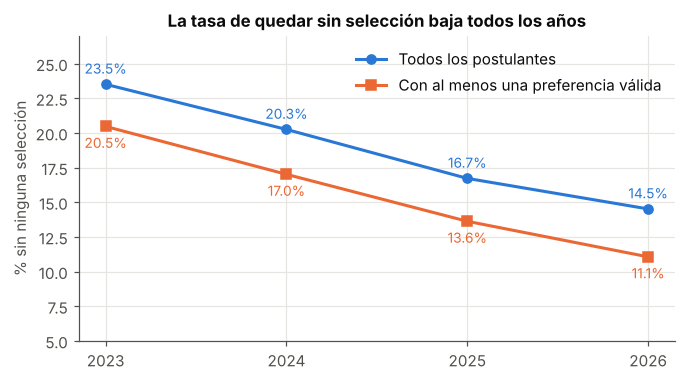

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(YEARS, rate["tasa (todos)"] * 100, marker="o", color=BLUE, lw=2, label="Todos los postulantes")
ax.plot(YEARS, rate["tasa (efectivos)"] * 100, marker="s", color=ORANGE, lw=2, label="Con al menos una preferencia válida")
for y in YEARS:
    ax.annotate(f"{rate.loc[y,'tasa (todos)']*100:.1f}%", (y, rate.loc[y, "tasa (todos)"] * 100), textcoords="offset points", xytext=(0, 7), ha="center", color=BLUE, fontsize=9)
    ax.annotate(f"{rate.loc[y,'tasa (efectivos)']*100:.1f}%", (y, rate.loc[y, "tasa (efectivos)"] * 100), textcoords="offset points", xytext=(0, -14), ha="center", color=ORANGE, fontsize=9)
ax.set_xticks(YEARS); ax.set_ylim(5, 27); ax.set_ylabel("% sin ninguna selección"); ax.legend(loc="upper right")
_ = ax.set_title("La tasa de quedar sin selección baja todos los años")

> **Lectura (importante para el diseño).** La reconciliación es exacta: el 14,5% de 2026 son las 27.492 personas del módulo 1, que se descomponen en 20.131 con alguna preferencia válida más 7.361 sin ninguna preferencia válida (estas últimas son todas `y = 1`).
>
> **La tasa no es estable:** cae de 23,5% (2023) a 14,5% (2026). Es un *cambio de prevalencia entre años*. Consecuencias: (i) un modelo entrenado con años anteriores verá más casos positivos que los que habrá el año siguiente, lo que descalibra las probabilidades (se mide en la sección 6); (ii) las conclusiones solo valen mientras el sistema se parezca al de 2024–2026 (condición de validez, análisis de negocio A1.2). Por eso la validación **debe** ser temporal.

## 2.4 Variables disponibles en t0  *(paso P4)*
Para cada postulante del año *t* se calculan las variables de la sección 1.4 usando solo la lista que armó, sus puntajes y los cortes del año *t − 1*.

In [6]:
def list_features(d, cut_prev, cut_prev2, year):
    # La lista tal como la armó el postulante = filas del cupo REGULAR (todos los postulantes tienen una por preferencia)
    r = d[d.TIPO_PREF == "REGULAR"][["MRUN", "ORDEN_PREF", "COD_CARRERA", "PTJE"]].copy()
    r["valid"] = r.PTJE > 0
    pp = cut_prev.set_index("COD_CARRERA")
    r["corte_prev"] = r.COD_CARRERA.map(pp.corte)
    r["n_sel_prev"] = r.COD_CARRERA.map(pp.n_sel)
    r["gap_prev"] = r.COD_CARRERA.map(pp.p5 - pp.corte)            # distancia entre el mínimo y el percentil 5 (corte ruidoso)
    r["holgura"] = np.where(r.valid, r.PTJE - r.corte_prev, np.nan)  # puntaje del postulante menos el corte del año pasado
    r["holgura_p5"] = np.where(r.valid, r.PTJE - r.COD_CARRERA.map(pp.p5), np.nan)
    r["sin_corte_prev"] = r.valid & r.corte_prev.isna()
    r["delta_prev"] = r.corte_prev - r.COD_CARRERA.map(cut_prev2.set_index("COD_CARRERA").corte) if cut_prev2 is not None else np.nan
    r["a0"], r["a30"], r["a60"] = r.holgura >= 0, r.holgura >= 30, r.holgura >= 60
    r["ptje_v"] = r.PTJE.where(r.valid)
    g = r.groupby("MRUN")
    f = pd.DataFrame({"n_prefs": g.size(), "n_valid": g.valid.sum(), "best_ptje": g.PTJE.max(), "mean_ptje": g.ptje_v.mean(),
                      "best_holgura": g.holgura.max(), "mean_holgura": g.holgura.mean(), "best_holgura_p5": g.holgura_p5.max(),
                      "n_above_0": g.a0.sum(), "n_above_30": g.a30.sum(), "n_above_60": g.a60.sum(), "n_sin_corte_prev": g.sin_corte_prev.sum()})
    f["share_valid"] = f.n_valid / f.n_prefs
    f["any_above_0"] = (f.best_holgura >= 0).astype(int)                       # regla del baseline B0
    f["holgura_pref1"] = r[r.ORDEN_PREF == 1].set_index("MRUN").holgura
    best = r.loc[r.dropna(subset=["holgura"]).groupby("MRUN").holgura.idxmax().values].set_index("MRUN")   # la opción más segura
    f["n_sel_prev_best"], f["gap_prev_best"], f["delta_prev_best"] = best.n_sel_prev, best.gap_prev, best.delta_prev
    tipos = pd.crosstab(d.MRUN, d.TIPO_PREF).clip(upper=1)                      # cupos a los que postula
    for t in ["PACE", "BEA", "GENERO"]:
        f["cupo_" + t.lower()] = tipos[t] if t in tipos.columns else 0
    return f.reset_index()

def socio_features(year):
    folder = DATA_ROOT / str(year)
    a_cols = ["MRUN", "COD_SEXO", "RAMA_EDUCACIONAL", "DEPENDENCIA", "PTJE_NEM", "PTJE_RANKING", "CLEC_MAX", "MATE1_MAX", "MATE2_MAX", "HCSOC_MAX", "CIEN_MAX"]
    a = pd.read_csv(next(folder.glob("A_INSCRITOS_PUNTAJES_PAES_*_PUB_MRUN.csv")), sep=";", encoding="utf-8-sig", dtype=str, usecols=a_cols)
    b = pd.read_csv(next(folder.glob("B_SOCIOECONOMICO_DOMICILIO_PAES_*_PUB_MRUN.csv")), sep=";", encoding="utf-8-sig", dtype=str,
                    usecols=["MRUN", "INGRESO_PERCAPITA_GRUPO_FA", "CODIGO_REGION_DOMICILIO"])
    score_cols = ["PTJE_NEM", "PTJE_RANKING", "CLEC_MAX", "MATE1_MAX", "MATE2_MAX", "HCSOC_MAX", "CIEN_MAX"]
    for c in score_cols:
        a[c] = pd.to_numeric(a[c], errors="coerce"); a.loc[a[c] == 0, c] = np.nan       # 0 = "no rindió"
    a["ptje_oblig"] = a[["CLEC_MAX", "MATE1_MAX"]].mean(axis=1, skipna=False)
    a["is_tp"] = a.RAMA_EDUCACIONAL.fillna("").str.startswith("T").astype(int)
    a["DEPENDENCIA"] = pd.to_numeric(a.DEPENDENCIA, errors="coerce"); a["MRUN"] = a.MRUN.astype(int); b["MRUN"] = b.MRUN.astype(int)
    b["ingreso_decil"] = pd.to_numeric(b.INGRESO_PERCAPITA_GRUPO_FA, errors="coerce").replace(99, np.nan)   # 99 = prefiere no responder
    b["region"] = pd.to_numeric(b.CODIGO_REGION_DOMICILIO, errors="coerce")
    m = a.drop(columns=["RAMA_EDUCACIONAL"]).merge(b[["MRUN", "ingreso_decil", "region"]], on="MRUN", how="left")
    m["sexo"] = pd.to_numeric(m.pop("COD_SEXO"), errors="coerce")
    return m

def build_cohort(year):
    cp2 = cuts[cuts.YEAR == year - 2]
    f = list_features(post[year], cuts[cuts.YEAR == year - 1], cp2 if len(cp2) else None, year)
    c = labels[year].reset_index().merge(f, on="MRUN", how="left").merge(socio_features(year), on="MRUN", how="left")
    c["year"] = year
    return c

cohort = {y: build_cohort(y) for y in [2024, 2025, 2026]}
for y, c in cohort.items():
    print(y, c.shape, "| tasa y (efectivos):", round(c[c.efectivo == 1].y.mean(), 4),
          "| % sin mejor_holgura:", round(c.best_holgura.isna().mean() * 100, 1), "| % sin ingreso:", round(c.ingreso_decil.isna().mean() * 100, 1))

2024 (188707, 38) | tasa y (efectivos): 0.1701 | % sin mejor_holgura: 4.2 | % sin ingreso: 26.7
2025 (189982, 38) | tasa y (efectivos): 0.1362 | % sin mejor_holgura: 3.9 | % sin ingreso: 27.9
2026 (189399, 38) | tasa y (efectivos): 0.1106 | % sin mejor_holgura: 4.3 | % sin ingreso: 28.1


## 2.5 Chequeo anti-fuga  *(validador de P4)*
Regla de la pauta: se calcula el **AUC de cada variable por separado**; un valor sobre **0,85 es sospechoso** y obliga a investigar. Se usa la cohorte 2025 (efectivos).

In [7]:
cand = ["n_prefs", "n_valid", "share_valid", "best_ptje", "mean_ptje", "best_holgura", "mean_holgura", "best_holgura_p5", "n_above_0", "n_above_30",
        "n_above_60", "n_sin_corte_prev", "holgura_pref1", "n_sel_prev_best", "gap_prev_best", "delta_prev_best", "ptje_oblig", "PTJE_NEM", "PTJE_RANKING",
        "is_tp", "DEPENDENCIA", "ingreso_decil", "cupo_pace", "cupo_bea", "cupo_genero"]
d25 = cohort[2025][cohort[2025].efectivo == 1]
rows = []
for f in cand:
    m = d25[f].notna()
    a = roc_auc_score(d25.y[m], d25.loc[m, f].astype(float)); rows.append({"variable": f, "AUC": round(max(a, 1 - a), 3), "% ausente": round((1 - m.mean()) * 100, 1)})
auc_tab = pd.DataFrame(rows).sort_values("AUC", ascending=False).reset_index(drop=True)
auc_tab["¿sospechosa (>0,85)?"] = np.where(auc_tab.AUC > 0.85, "SÍ: investigar", "")
auc_tab.head(12)

           variable    AUC  % ausente ¿sospechosa (>0,85)?
0   best_holgura_p5  0.971        0.3       SÍ: investigar
1      best_holgura  0.971        0.3       SÍ: investigar
2         n_above_0  0.949        0.0       SÍ: investigar
3        n_above_30  0.928        0.0       SÍ: investigar
4      mean_holgura  0.903        0.3       SÍ: investigar
5        n_above_60  0.886        0.0       SÍ: investigar
6     gap_prev_best  0.795        0.3                     
7     holgura_pref1  0.778        3.9                     
8         best_ptje  0.734        0.2                     
9         mean_ptje  0.723        0.2                     
10          n_valid  0.684        0.0                     
11       ptje_oblig  0.680        0.0                     

In [8]:
# Investigación de las variables sospechosas: prueba placebo.
# Si 'best_holgura' contuviera información del futuro, usar el corte del MISMO año (trampa deliberada) no debería cambiar nada.
# Si en cambio solo es una señal legítimamente fuerte, la trampa debería mejorar el AUC claramente.
r = post[2025][(post[2025].TIPO_PREF == "REGULAR") & (post[2025].PTJE > 0)].copy()
auc_lag = {}
for lag in [1, 0]:
    c = cuts[cuts.YEAR == 2025 - lag].set_index("COD_CARRERA").corte
    r["h"] = r.PTJE - r.COD_CARRERA.map(c)
    bh = r.groupby("MRUN").h.max()
    dd = d25.set_index("MRUN").join(bh.rename("bh")); dd = dd[dd.bh.notna()]
    auc_lag[lag] = roc_auc_score(dd.y, -dd.bh)
print(f"AUC de best_holgura con el corte del año anterior (legítimo): {auc_lag[1]:.3f}")
print(f"AUC de best_holgura con el corte del mismo año (TRAMPA):      {auc_lag[0]:.3f}")
RES["auc_best_holgura"] = {"legitimo": float(auc_lag[1]), "trampa": float(auc_lag[0])}

AUC de best_holgura con el corte del año anterior (legítimo): 0.971
AUC de best_holgura con el corte del mismo año (TRAMPA):      0.998


> **Conclusión del chequeo.** `best_holgura` (AUC ≈ 0,97), `best_holgura_p5` y las demás variables derivadas de la holgura superan el umbral de 0,85, **pero no son fuga**: usan solo el puntaje del postulante y el corte del año anterior, ambos conocidos antes del cierre; y la prueba placebo muestra que el corte *verdaderamente futuro* daría un AUC todavía mayor (≈ 0,998). Es simplemente una señal muy fuerte, que además explica por qué el baseline es difícil de superar. Se documenta la alarma, la investigación y la conclusión.
>
> Otro punto delicado: `PTJE_PREF` viene vacío exactamente cuando la preferencia es inválida. Se usa solo como "tiene o no tiene puntaje" (información que el postulante conoce al armar su lista), **nunca** el `ESTADO_PREF`, que distingue 24/25/26 y sí es el resultado.

# 3. ¿Cómo se valida? — Diseño de la validación  *(T2.1)*
**Cómo se usará el modelo:** cada año, antes del cierre, con un modelo entrenado en años anteriores y cortes del año anterior. La validación imita exactamente eso:

| Etapa | Entrenamiento | Evaluación | Para qué |
|---|---|---|---|
| **Diseño** | cohorte 2024 (cortes 2023) | cohorte 2025 (cortes 2024) | Elegir variables, hiperparámetros y regla de decisión |
| **Final** | cohortes 2024 + 2025 | cohorte 2026 (cortes 2025) | Medir el desempeño real, **una sola vez**, con todo congelado |

- La cohorte 2023 solo aporta cortes (para construir las variables de 2024): no hay cortes de 2022 comparables (proceso PDT).
- Los hiperparámetros se eligen por **validación cruzada estratificada de 5 (logit) o 3 (HistGB) pliegues dentro del entrenamiento**, nunca mirando la evaluación.
- **Grupos y clases especiales:** los postulantes se tratan como independientes entre sí dentro de un año; las alertas de postulantes PACE/BEA/género se auditan por separado en la sección 9. Un mismo postulante nunca aparece en dos años (se identifica por año).
- **Registro de honestidad:** antes de congelar el diseño solo se miró de 2026 (a) su tasa de etiqueta, para reconciliar con el módulo 1, y (b) el rendimiento de la regla B0, que no se ajusta. Ningún modelo, hiperparámetro, margen ni umbral se eligió con 2026.

# 4. Modelos
- **Interpretable:** regresión logística (con imputación + indicador de ausencia y estandarización).
- **Ensemble:** `HistGradientBoostingClassifier` con hiperparámetros por búsqueda aleatoria + CV.
- **Reglas:** B0, B1 (con margen) y las dos anclas triviales. **Todos se evalúan con la misma población, los mismos cortes, el mismo costo y el mismo umbral**, de modo que las comparaciones numéricas son directas.
- **Conjuntos de variables:** `F1` (lista + puntajes + cupos + robustez de cortes) y `F2` = `F1` + variables socioeducativas, para medir si estas últimas aportan algo.

In [9]:
COST_FN, COST_FP = 10.0, 1.0
def p_star(c_fn=COST_FN, c_fp=COST_FP): return c_fp / (c_fp + c_fn)      # umbral de Bayes
P_STAR = p_star()
print(f"p* teórico = {P_STAR:.4f}")

F1 = ["n_prefs", "n_valid", "share_valid", "best_ptje", "mean_ptje", "best_holgura", "mean_holgura", "n_above_0", "n_above_30", "n_above_60",
      "n_sin_corte_prev", "holgura_pref1", "best_holgura_p5", "n_sel_prev_best", "gap_prev_best", "ptje_oblig", "PTJE_NEM", "PTJE_RANKING",
      "cupo_pace", "cupo_bea", "cupo_genero"]                       # 'delta_prev_best' se prueba aparte: no existe para la cohorte 2024
F2 = F1 + ["is_tp", "DEPENDENCIA", "ingreso_decil"]

def make_linear(features, C=1.0):
    pre = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), features)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(C=C, max_iter=3000, random_state=SEED))])

def make_hgb(features, seed=SEED, **kw):
    params = dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=100, l2_regularization=1.0,
                  early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=seed)
    params.update(kw)
    return Pipeline([("pre", ColumnTransformer([("num", "passthrough", features)])), ("clf", HistGradientBoostingClassifier(**params))])

def expected_cost(y, alert, c_fn=COST_FN, c_fp=COST_FP):
    # costo por cada 1.000 postulantes: c_fn por cada "año perdido" sin alerta + c_fp por cada alerta innecesaria
    y = np.asarray(y); alert = np.asarray(alert).astype(bool)
    return 1000 * (c_fn * ((~alert) & (y == 1)).sum() + c_fp * (alert & (y == 0)).sum()) / len(y)

def rule_alert(df, margin=0.0):
    # B0 (margin=0): alerta si la mejor opción NO está sobre el corte del año pasado. B1: lo mismo con margen de seguridad.
    return (df.best_holgura.fillna(-1e9) < margin).values

def metrics(y, p, thr=P_STAR):
    y = np.asarray(y); a = p >= thr
    return {"cost_1000": expected_cost(y, a), "alert_rate": a.mean(), "recall": (a & (y == 1)).sum() / (y == 1).sum(),
            "precision": (a & (y == 1)).sum() / max(a.sum(), 1), "AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p),
            "logloss": log_loss(y, p), "brier": brier_score_loss(y, p)}

def tune_margin(df, c_fn=COST_FN, c_fp=COST_FP, grid=np.arange(-60, 121, 5)):
    costs = [expected_cost(df.y, rule_alert(df, m), c_fn, c_fp) for m in grid]
    return float(grid[int(np.argmin(costs))])

def boot_costs(y, alerts, B=300, seed=SEED, c_fn=COST_FN, c_fp=COST_FP):
    # Bootstrap de Poisson PAREADO: los mismos pesos para todos los métodos, así la diferencia entre métodos tiene su propia incertidumbre
    r = np.random.default_rng(seed); y = np.asarray(y)
    fn = {k: ((~a) & (y == 1)).astype(float) for k, a in alerts.items()}; fp = {k: (a & (y == 0)).astype(float) for k, a in alerts.items()}
    out = {k: np.empty(B) for k in alerts}
    for b in range(B):
        w = r.poisson(1.0, len(y)); sw = w.sum()
        for k in alerts: out[k][b] = 1000 * (c_fn * (w * fn[k]).sum() + c_fp * (w * fp[k]).sum()) / sw
    return out

def ci(x): return f"[{np.percentile(x, 2.5):.1f}; {np.percentile(x, 97.5):.1f}]"

def tune_logit(df, features, Cs=(0.001, 0.01, 0.1, 1, 10, 100)):
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED); res = {}
    for C in Cs:
        p = cross_val_predict(make_linear(features, C), df[features], df.y, cv=cv, method="predict_proba")[:, 1]; res[C] = log_loss(df.y, p)
    return min(res, key=res.get), res

def tune_hgb(df, features, n_iter=8):
    space = dict(learning_rate=[0.03, 0.05, 0.1], max_leaf_nodes=[7, 15, 31], min_samples_leaf=[50, 100, 300], l2_regularization=[0, 1, 10])
    cv = StratifiedKFold(3, shuffle=True, random_state=SEED); trials = []
    for pr in ParameterSampler(space, n_iter=n_iter, random_state=SEED):
        p = cross_val_predict(make_hgb(features, **pr), df[features], df.y, cv=cv, method="predict_proba")[:, 1]
        trials.append((log_loss(df.y, p), pr))
    best = min(trials, key=lambda t: t[0]); return best[1], trials

p* teórico = 0.0909


## 4.1 Etapa de diseño: entrenar con 2024, evaluar en 2025
Primero las **tres anclas con el mismo costo y población**: nadie / todos / baseline. *Validador:* B0 debe quedar entre las dos triviales, si no hay un error.

In [10]:
TR = cohort[2024][cohort[2024].efectivo == 1].reset_index(drop=True)
VA = cohort[2025][cohort[2025].efectivo == 1].reset_index(drop=True)
yv = VA.y.values
m_star = tune_margin(TR)                                            # margen de B1, ajustado SOLO con 2024
anchors = pd.Series({"Nadie recibe alerta": expected_cost(yv, np.zeros(len(VA))), "Todos reciben alerta": expected_cost(yv, np.ones(len(VA))),
                     "B0: regla de hoy (margen 0)": expected_cost(yv, rule_alert(VA, 0)), f"B1: regla con margen {m_star:+.0f} pts": expected_cost(yv, rule_alert(VA, m_star))},
                    name="costo por 1.000 (2025)")
print(f"Entrenamiento: {len(TR):,} postulantes (tasa {TR.y.mean():.3f}) · Evaluación: {len(VA):,} (tasa {VA.y.mean():.3f})")
display(anchors.round(1))
assert anchors["B0: regla de hoy (margen 0)"] < min(anchors["Nadie recibe alerta"], anchors["Todos reciben alerta"]), "B0 debería quedar entre las anclas"

Entrenamiento: 181,340 postulantes (tasa 0.170) · Evaluación: 183,174 (tasa 0.136)
Nadie recibe alerta             1362.4
Todos reciben alerta             863.8
B0: regla de hoy (margen 0)      251.1
B1: regla con margen +40 pts     183.9


In [11]:
t0 = time.time()
C_best, logit_cv = tune_logit(TR, F1)
hgb_best, hgb_trials = tune_hgb(TR, F1)
print("Logit: C =", C_best, "| log-loss CV por C:", {k: round(v, 4) for k, v in logit_cv.items()})
print("HistGB: mejores hiperparámetros =", hgb_best, "| log-loss CV =", round(min(t[0] for t in hgb_trials), 4),
      "| rango entre configuraciones:", round(min(t[0] for t in hgb_trials), 4), "-", round(max(t[0] for t in hgb_trials), 4), f"({time.time()-t0:.0f}s)")

Logit: C = 1 | log-loss CV por C: {0.001: 0.1659, 0.01: 0.159, 0.1: 0.1585, 1: 0.1585, 10: 0.1585, 100: 0.1585}
HistGB: mejores hiperparámetros = {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'learning_rate': 0.1, 'l2_regularization': 0} | log-loss CV = 0.1119 | rango entre configuraciones: 0.1119 - 0.1376 (90s)


In [12]:
def fit_predict(make, feats, tr, te):
    return make().fit(tr[feats], tr.y).predict_proba(te[feats])[:, 1]

P = {"Logit 1 variable (best_holgura)": fit_predict(lambda: make_linear(["best_holgura"], C_best), ["best_holgura"], TR, VA),
     "Logit F1": fit_predict(lambda: make_linear(F1, C_best), F1, TR, VA),
     "Logit F2 (+socioeducativas)": fit_predict(lambda: make_linear(F2, C_best), F2, TR, VA)}
hgb_seeds = [make_hgb(F1, seed=s, **hgb_best).fit(TR[F1], TR.y).predict_proba(VA[F1])[:, 1] for s in range(5)]
P["HistGB F1"] = hgb_seeds[0]
P["HistGB F2 (+socioeducativas)"] = make_hgb(F2, **hgb_best).fit(TR[F2], TR.y).predict_proba(VA[F2])[:, 1]

design = pd.DataFrame({k: metrics(yv, p) for k, p in P.items()}).T
for name, a in [("B0: regla de hoy", rule_alert(VA, 0)), (f"B1: margen {m_star:+.0f}", rule_alert(VA, m_star))]:
    design.loc[name] = {"cost_1000": expected_cost(yv, a), "alert_rate": a.mean(), "recall": (a & (yv == 1)).sum() / (yv == 1).sum(),
                        "precision": (a & (yv == 1)).sum() / a.sum()}
display(design.round(4).sort_values("cost_1000"))
print("\nHistGB F1, 5 semillas -> costo/1000:", [round(expected_cost(yv, p >= P_STAR), 1) for p in hgb_seeds], "| AUC:", [round(roc_auc_score(yv, p), 4) for p in hgb_seeds])

                                 cost_1000  alert_rate  recall  precision     AUC  PR_AUC  logloss   brier
HistGB F1                         168.5610      0.2485  0.9625     0.5276  0.9771  0.8899   0.1368  0.0418
HistGB F2 (+socioeducativas)      171.0286      0.2540  0.9645     0.5173  0.9768  0.8854   0.1400  0.0424
B1: margen +40                    183.9344      0.2640  0.9625     0.4967     NaN     NaN      NaN     NaN
Logit F2 (+socioeducativas)       184.8297      0.2820  0.9739     0.4706  0.9733  0.8657   0.1502  0.0466
Logit F1                          185.5231      0.2825  0.9738     0.4696  0.9733  0.8655   0.1502  0.0466
Logit 1 variable (best_holgura)   204.3085      0.3039  0.9756     0.4373  0.9706  0.8573   0.1532  0.0455
B0: regla de hoy                  251.0837      0.1654  0.8519     0.7018     NaN     NaN      NaN     NaN

HistGB F1, 5 semillas -> costo/1000: [np.float64(168.6), np.float64(169.1), np.float64(170.7), np.float64(168.5), np.float64(168.5)] | AUC: [0.

In [13]:
# Incertidumbre: bootstrap pareado sobre los postulantes de 2025
alerts = {"B0": rule_alert(VA, 0), "B1": rule_alert(VA, m_star), "Logit F1": P["Logit F1"] >= P_STAR, "HistGB F1": P["HistGB F1"] >= P_STAR,
          "Logit F2": P["Logit F2 (+socioeducativas)"] >= P_STAR, "HistGB F2": P["HistGB F2 (+socioeducativas)"] >= P_STAR}
bc = boot_costs(yv, alerts)
comp = {"Logit F1 − B0": bc["Logit F1"] - bc["B0"], "HistGB F1 − B0": bc["HistGB F1"] - bc["B0"], "B1 − B0": bc["B1"] - bc["B0"],
        "Logit F1 − B1": bc["Logit F1"] - bc["B1"], "HistGB F1 − B1": bc["HistGB F1"] - bc["B1"], "HistGB F1 − Logit F1": bc["HistGB F1"] - bc["Logit F1"],
        "HistGB F2 − HistGB F1 (aporte socioeducativo)": bc["HistGB F2"] - bc["HistGB F1"]}
tab = pd.DataFrame({k: {"Δ costo/1000 (media)": v.mean(), "IC 95%": ci(v)} for k, v in comp.items()}).T
display(tab)
RES["design"] = {"anchors": anchors.round(2).to_dict(), "margin_B1": m_star, "models": design.round(4).to_dict(orient="index")}

                                              Δ costo/1000 (media)          IC 95%
Logit F1 − B0                                           -65.503158  [-70.9; -59.7]
HistGB F1 − B0                                          -82.354852  [-87.8; -76.8]
B1 − B0                                                   -67.1906  [-72.8; -62.1]
Logit F1 − B1                                             1.687441     [-1.1; 4.7]
HistGB F1 − B1                                          -15.164252  [-18.6; -11.8]
HistGB F1 − Logit F1                                    -16.851693  [-19.6; -14.2]
HistGB F2 − HistGB F1 (aporte socioeducativo)             2.500566      [0.8; 4.0]


Umbral empírico óptimo: {'Logit F1': np.float64(0.13), 'HistGB F1': np.float64(0.11)} | rango dentro del 2% del óptimo: {'Logit F1': (np.float64(0.11), np.float64(0.19)), 'HistGB F1': (np.float64(0.08), np.float64(0.15))}
Promedio de probabilidad predicha vs tasa real 2025: {'Logit F1': np.float64(0.167), 'HistGB F1': np.float64(0.158)} vs 0.136


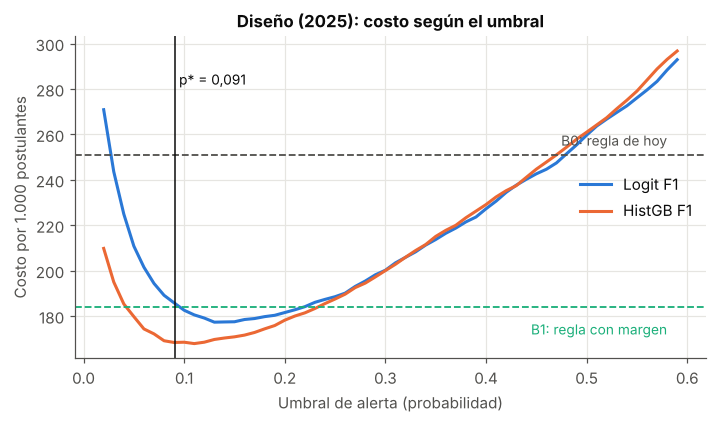

In [14]:
# Curva costo vs umbral (2025): ¿cae el umbral teórico p* dentro del rango casi-óptimo de la curva empírica?
thr = np.round(np.arange(0.02, 0.60, 0.01), 2)
fig, ax = plt.subplots(figsize=(7.4, 3.8))
for name, col in [("Logit F1", BLUE), ("HistGB F1", ORANGE)]:
    ax.plot(thr, [expected_cost(yv, P[name] >= t) for t in thr], color=col, lw=2, label=name)
ax.axhline(anchors["B0: regla de hoy (margen 0)"], color=MUTED, ls="--", lw=1.2); ax.text(0.58, anchors["B0: regla de hoy (margen 0)"] + 4, "B0: regla de hoy", ha="right", color=MUTED, fontsize=9)
ax.axhline(anchors[f"B1: regla con margen {m_star:+.0f} pts"], color=AQUA, ls="--", lw=1.2); ax.text(0.58, anchors[f"B1: regla con margen {m_star:+.0f} pts"] - 12, "B1: regla con margen", ha="right", color=AQUA, fontsize=9)
ax.axvline(P_STAR, color=INK, lw=1); ax.text(P_STAR + 0.004, ax.get_ylim()[1] * 0.93, "p* = 0,091", fontsize=9)
ax.set_xlabel("Umbral de alerta (probabilidad)"); ax.set_ylabel("Costo por 1.000 postulantes"); ax.legend(loc="center right")
_ = ax.set_title("Diseño (2025): costo según el umbral")
best_thr = {n: thr[int(np.argmin([expected_cost(yv, P[n] >= t) for t in thr]))] for n in ["Logit F1", "HistGB F1"]}
rng_ok = {n: [t for t in thr if expected_cost(yv, P[n] >= t) <= 1.02 * min(expected_cost(yv, P[n] >= u) for u in thr)] for n in best_thr}
print("Umbral empírico óptimo:", best_thr, "| rango dentro del 2% del óptimo:", {n: (min(v), max(v)) for n, v in rng_ok.items()})
print("Promedio de probabilidad predicha vs tasa real 2025:", {n: round(P[n].mean(), 3) for n in ["Logit F1", "HistGB F1"]}, "vs", round(yv.mean(), 3))

> **Lectura del diseño (2025).**
> 1. **Todos los modelos le ganan claramente a B0**, la regla de hoy (diferencias de −65 a −82 puntos de costo por 1.000, con intervalos que no tocan el cero).
> 2. **Pero B1**, la *misma regla simple* con un margen de seguridad de unos 40 puntos ajustado con 2024, **recupera casi toda esa ventaja** (−67). Es un resultado que conviene decir con claridad: gran parte de la mejora respecto a la regla de hoy se logra solo alertando a quien tiene una holgura menor a ≈ 40 puntos, sin ML.
> 3. **Frente a B1, solo el ensemble aporta algo:** el HistGB reduce el costo en ≈ 15 puntos (IC95% sin cero) y la regresión logística **no se distingue de B1** (diferencia +1,7, IC que incluye el cero). El ensemble supera al logit en ≈ 17 puntos.
> 4. **Las variables socioeducativas (F2) no mejoran** el costo (incluso lo empeoran levemente), así que se dejan fuera del modelo propuesto: es la opción más simple y la más prudente en términos de equidad.
> 5. **Calibración:** la probabilidad promedio predicha queda por encima de la tasa real (15,8% el HistGB y 16,7% el logit, contra 13,6%) por el cambio de prevalencia entre 2024 y 2025. Para el HistGB el umbral teórico (0,091) cae **dentro** del rango casi-óptimo de la curva empírica (0,08 a 0,15); para el logit no (0,11 a 0,19), señal de que requeriría recalibración.

## 4.2 Extensiones evaluadas en la etapa de diseño  *(T2.3 y T4.3)*
**(a) Corrección de la descalibración sin etiquetas (EM de Saerens).** Es un método para estimar la nueva prevalencia solo con las variables del año nuevo (sin conocer quién quedó sin selección) y reajustar las probabilidades. Lo probamos porque la tasa baja cada año.

**(b) Reversión del corte** (`delta_prev_best`: cuánto cambió el corte el año anterior). Solo existe desde la cohorte 2025, así que no se puede evaluar de forma temporal en la etapa de diseño; se prueba con validación cruzada *dentro de 2025* como indicio, y se evalúa de forma temporal solo al final (sección 5.3).

In [15]:
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
sig = lambda z: 1 / (1 + np.exp(-z))
def shift_prior(p, pi_old, pi_new): return sig(logit(p) + np.log(pi_new / (1 - pi_new)) - np.log(pi_old / (1 - pi_old)))
def em_prior(p, pi_old, it=100):
    pi = pi_old
    for _ in range(it): pi = shift_prior(p, pi_old, pi).mean()
    return pi

p_h = P["HistGB F1"]; pi_old = TR.y.mean(); pi_em = em_prior(p_h, pi_old)
for name, q in [("sin corregir", p_h), ("EM (solo con variables, sin etiquetas)", shift_prior(p_h, pi_old, pi_em)), ("oráculo (usando la tasa real de 2025)", shift_prior(p_h, pi_old, yv.mean()))]:
    print(f"{name:42s} prevalencia media predicha = {q.mean():.3f} | log-loss = {log_loss(yv, q):.4f} | costo en p* = {expected_cost(yv, q >= P_STAR):.1f}")
print(f"\nPrevalencia real 2025: {yv.mean():.3f} | estimada por EM: {pi_em:.3f}  -> EM NO logra capturar la caída")

# (b) reversión del corte: validación cruzada dentro de 2025 (indicio, no es validación temporal)
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
for name, fs in [("F1", F1), ("F1 + delta_prev_best", F1 + ["delta_prev_best"])]:
    p = cross_val_predict(make_hgb(fs, **hgb_best), VA[fs], VA.y, cv=cv5, method="predict_proba")[:, 1]
    print(f"[CV dentro de 2025] HistGB {name:22s} log-loss = {log_loss(VA.y, p):.4f} | AUC = {roc_auc_score(VA.y, p):.4f} | costo/1000 = {expected_cost(VA.y, p >= P_STAR):.1f}")

sin corregir                               prevalencia media predicha = 0.158 | log-loss = 0.1368 | costo en p* = 168.6
EM (solo con variables, sin etiquetas)     prevalencia media predicha = 0.154 | log-loss = 0.1344 | costo en p* = 168.5
oráculo (usando la tasa real de 2025)      prevalencia media predicha = 0.149 | log-loss = 0.1322 | costo en p* = 168.1

Prevalencia real 2025: 0.136 | estimada por EM: 0.154  -> EM NO logra capturar la caída
[CV dentro de 2025] HistGB F1                     log-loss = 0.0974 | AUC = 0.9874 | costo/1000 = 116.7
[CV dentro de 2025] HistGB F1 + delta_prev_best   log-loss = 0.0874 | AUC = 0.9900 | costo/1000 = 99.8


> **Resultados de las extensiones.**
> - **(a) La corrección EM ayuda muy poco:** estima una prevalencia de ≈ 15,4% cuando la real fue 13,6% (la predicción sin corregir era 15,8%), porque lo que cambió entre años no fue solo la prevalencia (también cambió la relación entre variables y resultado). Incluso el *oráculo* (que usaría la tasa real, desconocida al decidir) mejora la log-loss solo de 0,137 a 0,132 y **casi no cambia el costo** (168,6 → 168,1). **Se descarta** y se mantiene el umbral teórico.
> - **(b) La reversión del corte promete** (dentro de 2025, la log-loss cae de ≈ 0,097 a ≈ 0,087 y el costo de ≈ 117 a ≈ 100 por 1.000), pero este número **no es temporal** y no puede confirmarse con 2024 → 2025. Se deja como extensión a verificar en 2026 (sección 5.3), declarando que ese modelo solo puede entrenarse con 2025.

## 4.3 Decisiones congeladas antes de abrir 2026

In [16]:
FROZEN = {"población": "postulantes con >=1 preferencia válida; los demás: alerta fija", "etiqueta": "sin ESTADO 24 en ningún cupo",
          "modelo propuesto": "HistGradientBoosting con variables F1 (sin socioeducativas)", "modelo interpretable": "Regresión logística con F1",
          "hiperparámetros": "se re-buscan con el mismo procedimiento sobre 2024+2025 (solo con CV interna)", "umbral": f"p* teórico = {P_STAR:.4f} (razón de costos 10:1)",
          "comparador principal": "B1 (regla con margen ajustado en entrenamiento)", "corrección de prevalencia": "ninguna (EM descartado)",
          "variable delta_prev_best": "solo como extensión declarada (entrenada con 2025)"}
print("Decisiones congeladas el", pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "-> a partir de aquí se usa la cohorte 2026 por primera vez para evaluar modelos")
for k, v in FROZEN.items(): print(f" - {k}: {v}")
RES["frozen"] = FROZEN

Decisiones congeladas el 2026-11-14 20:19 -> a partir de aquí se usa la cohorte 2026 por primera vez para evaluar modelos
 - población: postulantes con >=1 preferencia válida; los demás: alerta fija
 - etiqueta: sin ESTADO 24 en ningún cupo
 - modelo propuesto: HistGradientBoosting con variables F1 (sin socioeducativas)
 - modelo interpretable: Regresión logística con F1
 - hiperparámetros: se re-buscan con el mismo procedimiento sobre 2024+2025 (solo con CV interna)
 - umbral: p* teórico = 0.0909 (razón de costos 10:1)
 - comparador principal: B1 (regla con margen ajustado en entrenamiento)
 - corrección de prevalencia: ninguna (EM descartado)
 - variable delta_prev_best: solo como extensión declarada (entrenada con 2025)


# 5. Evaluación final en 2026 (una sola vez)  *(T2.2, T3.1)*
Con todo congelado, se vuelve a entrenar con **2024 + 2025** usando el mismo procedimiento (búsqueda de hiperparámetros y margen de B1 solo con validación cruzada interna) y se evalúa en la cohorte **2026**, que ningún modelo había visto.

In [17]:
TRF = pd.concat([cohort[2024], cohort[2025]]); TRF = TRF[TRF.efectivo == 1].reset_index(drop=True)
TE = cohort[2026][cohort[2026].efectivo == 1].reset_index(drop=True); yt = TE.y.values
print(f"Entrenamiento 2024+2025: {len(TRF):,} (tasa {TRF.y.mean():.3f}) · Prueba 2026: {len(TE):,} (tasa {TE.y.mean():.3f})")
t0 = time.time()
C_f, _ = tune_logit(TRF, F1)
hgb_f, trials_f = tune_hgb(TRF, F1)
m_f = tune_margin(TRF)
print(f"Logit C = {C_f} · HistGB = {hgb_f} (log-loss CV {min(t[0] for t in trials_f):.4f}) · margen de B1 = {m_f:+.0f} puntos ({time.time()-t0:.0f}s)")

Entrenamiento 2024+2025: 364,514 (tasa 0.153) · Prueba 2026: 182,038 (tasa 0.111)
Logit C = 10 · HistGB = {'min_samples_leaf': 100, 'max_leaf_nodes': 31, 'learning_rate': 0.05, 'l2_regularization': 10} (log-loss CV 0.1138) · margen de B1 = +35 puntos (155s)


In [18]:
lg = make_linear(F1, C_f).fit(TRF[F1], TRF.y);                    p_lg = lg.predict_proba(TE[F1])[:, 1]
hg_models = [make_hgb(F1, seed=s, **hgb_f).fit(TRF[F1], TRF.y) for s in range(5)]
p_hg_all = [m.predict_proba(TE[F1])[:, 1] for m in hg_models];    p_hg = p_hg_all[0]
PF = {"Logit F1": p_lg, "HistGB F1": p_hg}

rows = {"Nadie recibe alerta": np.zeros(len(TE), bool), "Todos reciben alerta": np.ones(len(TE), bool),
        "B0: regla de hoy (margen 0)": rule_alert(TE, 0), f"B1: regla con margen {m_f:+.0f}": rule_alert(TE, m_f),
        "Logit F1": p_lg >= P_STAR, "HistGB F1": p_hg >= P_STAR}
def row(y, a, p=None):
    d = {"costo/1000": expected_cost(y, a), "tasa de alerta": a.mean(), "recall": (a & (y == 1)).sum() / (y == 1).sum(),
         "precisión": (a & (y == 1)).sum() / max(a.sum(), 1)}
    if p is not None: d.update({"AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "log-loss": log_loss(y, p), "Brier": brier_score_loss(y, p)})
    return d
final = pd.DataFrame({k: row(yt, a, PF.get(k)) for k, a in rows.items()}).T
display(final.round(4))
print("\nHistGB F1, 5 semillas -> costo/1000:", [round(expected_cost(yt, p >= P_STAR), 1) for p in p_hg_all],
      "| AUC:", [round(roc_auc_score(yt, p), 4) for p in p_hg_all])

                             costo/1000  tasa de alerta  recall  precisión     AUC  PR-AUC  log-loss   Brier
Nadie recibe alerta           1105.8680          0.0000  0.0000     0.0000     NaN     NaN       NaN     NaN
Todos reciben alerta           889.4132          1.0000  1.0000     0.1106     NaN     NaN       NaN     NaN
B0: regla de hoy (margen 0)    180.6766          0.1391  0.8749     0.6955     NaN     NaN       NaN     NaN
B1: regla con margen +35       150.7652          0.2215  0.9673     0.4829     NaN     NaN       NaN     NaN
Logit F1                       146.8979          0.2299  0.9773     0.4701  0.9812  0.8755    0.1135  0.0336
HistGB F1                      132.1922          0.2156  0.9777     0.5014  0.9846  0.9057    0.1009  0.0306

HistGB F1, 5 semillas -> costo/1000: [np.float64(132.2), np.float64(133.0), np.float64(133.7), np.float64(131.7), np.float64(133.1)] | AUC: [0.9846, 0.9843, 0.9843, 0.9845, 0.9843]


                     Δ costo/1000 (media)          IC 95%
Logit F1 − B0                  -34.064417  [-38.8; -29.1]
HistGB F1 − B0                 -48.745805  [-53.5; -43.6]
B1 − B0                        -30.172555  [-34.5; -25.9]
Logit F1 − B1                   -3.891863    [-6.0; -1.7]
HistGB F1 − B1                  -18.57325  [-21.4; -16.2]
HistGB F1 − Logit F1           -14.681387  [-16.8; -12.6]


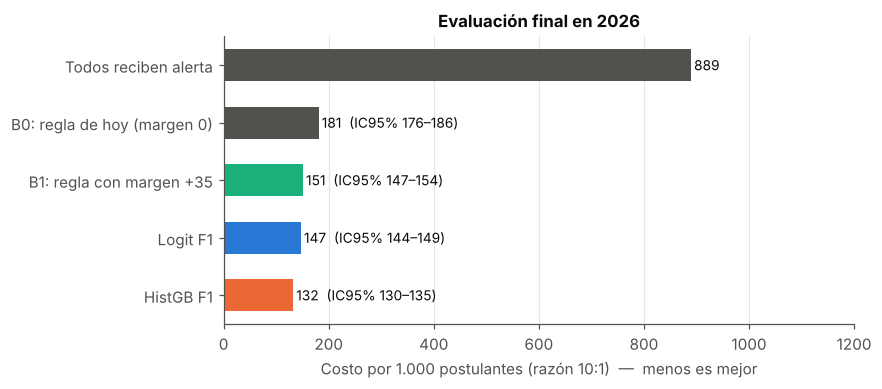

In [19]:
# Incertidumbre del resultado final: bootstrap pareado (300 remuestras de los postulantes de 2026)
BAL = {k: v for k, v in rows.items() if k not in ("Nadie recibe alerta", "Todos reciben alerta")}
bcf = boot_costs(yt, BAL)
kB0, kB1 = "B0: regla de hoy (margen 0)", f"B1: regla con margen {m_f:+.0f}"
cmp_final = {"Logit F1 − B0": bcf["Logit F1"] - bcf[kB0], "HistGB F1 − B0": bcf["HistGB F1"] - bcf[kB0], "B1 − B0": bcf[kB1] - bcf[kB0],
             "Logit F1 − B1": bcf["Logit F1"] - bcf[kB1], "HistGB F1 − B1": bcf["HistGB F1"] - bcf[kB1], "HistGB F1 − Logit F1": bcf["HistGB F1"] - bcf["Logit F1"]}
tab_f = pd.DataFrame({k: {"Δ costo/1000 (media)": v.mean(), "IC 95%": ci(v)} for k, v in cmp_final.items()}).T
display(tab_f)
cost_ci = {k: (bcf[k].mean(), np.percentile(bcf[k], 2.5), np.percentile(bcf[k], 97.5)) for k in BAL}

fig, ax = plt.subplots(figsize=(7.4, 3.4))
names = ["Todos reciben alerta", kB0, kB1, "Logit F1", "HistGB F1"]
vals = [expected_cost(yt, rows[n]) for n in names]
cols = [MUTED, MUTED, AQUA, BLUE, ORANGE]
ypos = np.arange(len(names))[::-1]
ax.barh(ypos, vals, color=cols, height=0.55)
for yp, n, v in zip(ypos, names, vals):
    lab = f"{v:.0f}" + (f"  (IC95% {cost_ci[n][1]:.0f}–{cost_ci[n][2]:.0f})" if n in cost_ci else "")
    ax.text(v + 6, yp, lab, va="center", fontsize=9, color=INK)
ax.set_yticks(ypos); ax.set_yticklabels(names); ax.set_xlim(0, max(vals) * 1.35); ax.set_xlabel("Costo por 1.000 postulantes (razón 10:1)  —  menos es mejor")
ax.grid(axis="y", visible=False); _ = ax.set_title("Evaluación final en 2026")

## 5.1 ¿Qué significa en personas?  *(traducción a costos y beneficios, A1.1)*
Con el mismo umbral y la misma población, estas son las cantidades de personas de 2026 (efectivos: 182.038; de ellos 20.131 quedaron sin selección):

In [20]:
def counts(a):
    tp = int((a & (yt == 1)).sum()); fp = int((a & (yt == 0)).sum()); fn = int((~a & (yt == 1)).sum())
    return {"alertas emitidas": int(a.sum()), "alertas útiles (TP)": tp, "alertas innecesarias (FP)": fp, "casos sin alerta que fallaron (FN)": fn,
            "costo total (10·FN + FP)": int(10 * fn + fp)}
ppl = pd.DataFrame({k: counts(rows[k]) for k in [kB0, kB1, "HistGB F1"]}).T
display(ppl)
RES["final_people"] = ppl.to_dict(orient="index")
fn0, fn1, fnm = ppl.loc[kB0, "casos sin alerta que fallaron (FN)"], ppl.loc[kB1, "casos sin alerta que fallaron (FN)"], ppl.loc["HistGB F1", "casos sin alerta que fallaron (FN)"]
print(f"\nVs. la regla de hoy (B0), el HistGB deja de dejar sin aviso a {fn0 - fnm:,} personas que perdieron el año, "
      f"a cambio de {ppl.loc['HistGB F1','alertas innecesarias (FP)'] - ppl.loc[kB0,'alertas innecesarias (FP)']:,} alertas innecesarias adicionales.")
print(f"Vs. la regla con margen (B1): {fn1 - fnm:,} personas menos sin aviso, con {ppl.loc['HistGB F1','alertas innecesarias (FP)'] - ppl.loc[kB1,'alertas innecesarias (FP)']:+,} alertas innecesarias.")
# Sistema completo: los 7.361 postulantes sin ninguna preferencia válida reciben una alerta fija ("su lista no tiene ninguna opción válida")
n_inv = int((cohort[2026].efectivo == 0).sum()); print(f"Más {n_inv:,} postulantes sin ninguna preferencia válida, que reciben la alerta fija (todos terminaron sin selección).")

                             alertas emitidas  alertas útiles (TP)  alertas innecesarias (FP)  casos sin alerta que fallaron (FN)  costo total (10·FN + FP)
B0: regla de hoy (margen 0)             25323                17613                       7710                                2518                     32890
B1: regla con margen +35                40327                19472                      20855                                 659                     27445
HistGB F1                               39256                19682                      19574                                 449                     24064

Vs. la regla de hoy (B0), el HistGB deja de dejar sin aviso a 2,069 personas que perdieron el año, a cambio de 11,864 alertas innecesarias adicionales.
Vs. la regla con margen (B1): 210 personas menos sin aviso, con -1,281 alertas innecesarias.
Más 7,361 postulantes sin ninguna preferencia válida, que reciben la alerta fija (todos terminaron sin selección).


In [21]:
# Capacidad limitada: si solo se puede contactar a las k personas de mayor riesgo, ¿a cuántas de las que fallan se llega?
order_m = np.argsort(-p_hg); order_b = np.argsort(TE.best_holgura.fillna(-1e9).values)        # B: primero la menor holgura
cap = pd.DataFrame([{"personas contactadas (k)": k, "recall HistGB": yt[order_m[:k]].sum() / yt.sum(), "precisión HistGB": yt[order_m[:k]].mean(),
                     "recall ranking por holgura": yt[order_b[:k]].sum() / yt.sum(), "precisión ranking por holgura": yt[order_b[:k]].mean()} for k in [5000, 10000, 20000, 30000, int((p_hg >= P_STAR).sum())]]).set_index("personas contactadas (k)")
display(cap.round(3)); RES["capacity"] = cap.round(4).to_dict(orient="index")

                          recall HistGB  precisión HistGB  recall ranking por holgura  precisión ranking por holgura
personas contactadas (k)                                                                                            
5000                              0.248             0.997                       0.209                          0.840
10000                             0.484             0.974                       0.422                          0.850
20000                             0.813             0.818                       0.761                          0.766
30000                             0.936             0.628                       0.925                          0.621
39256                             0.978             0.501                       0.964                          0.494


> **Lectura de la evaluación final (2026, razón de costos 10:1).**
> - **Orden de los métodos:** HistGB (132) < regresión logística (147) < regla con margen B1 (151) < regla de hoy B0 (181). Las diferencias pareadas tienen intervalos que no tocan el cero: HistGB − B1 = **-18,6** (IC95% -21,4 a -16,2), HistGB − B0 = -48,7, Logit − B1 = -3,9 (IC95% -6,0 a -1,7).
> - **Consistencia entre las dos evaluaciones temporales:** en el diseño (2025) el HistGB superaba a B1 por unos 15 puntos y en la evaluación final (2026) por unos 19; el logit pasó de empatar con B1 a una ventaja pequeña (≈ 4). El orden de los métodos se mantiene.
> - **En personas:** de las 20.131 que quedaron sin selección entre 182.038 postulantes con lista válida, la regla de hoy dejó sin aviso a 2.518 y el HistGB a 449. Ese avance se paga con más alertas: 39.256 contra 25.323 de la regla de hoy, y **la mitad de las alertas (precisión ≈ 50%) son innecesarias**. Frente a B1, el HistGB mejora en ambos errores a la vez (menos casos sin aviso y menos alertas innecesarias).
> - **Si la capacidad de contacto es limitada:** al contactar a las 20.000 personas de mayor riesgo se llega al 81% de quienes fallan (con el ranking por holgura simple, 76%), y con 10.000 contactos la precisión del ranking del modelo es 97%.
> - **Estabilidad:** con 5 semillas el costo del HistGB varía entre 131,7 y 133,7: la variación por semilla es mucho menor que la diferencia con B1.

## 5.2 Sensibilidad a la razón de costos
La razón 10:1 es un supuesto. Se recalcula con otras razones (cada una con su propio umbral de Bayes `p* = 1/(1+razón)` y su propio margen para B1, ajustado en entrenamiento):

In [22]:
sens = []
for ratio in [3, 5, 10, 20, 40]:
    ps = p_star(c_fn=ratio); mg = tune_margin(TRF, c_fn=ratio)
    sens.append({"razón FN:FP": f"{ratio}:1", "p*": round(ps, 3), "margen B1": mg,
                 "B0": expected_cost(yt, rule_alert(TE, 0), c_fn=ratio), "B1": expected_cost(yt, rule_alert(TE, mg), c_fn=ratio),
                 "Logit F1": expected_cost(yt, p_lg >= ps, c_fn=ratio), "HistGB F1": expected_cost(yt, p_hg >= ps, c_fn=ratio),
                 "todos alertados": expected_cost(yt, np.ones(len(yt), bool), c_fn=ratio)})
sens = pd.DataFrame(sens).set_index("razón FN:FP"); sens["HistGB vs B1 (%)"] = (sens["HistGB F1"] / sens["B1"] - 1) * 100
display(sens.round({"p*": 3, "margen B1": 0, "B0": 1, "B1": 1, "Logit F1": 1, "HistGB F1": 1, "todos alertados": 1, "HistGB vs B1 (%)": 1})); RES["sensitivity"] = sens.round(2).to_dict(orient="index")

                p*  margen B1     B0     B1  Logit F1  HistGB F1  todos alertados  HistGB vs B1 (%)
razón FN:FP                                                                                        
3:1          0.250       10.0   83.9   85.0      83.9       79.3            889.4              -6.7
5:1          0.167       20.0  111.5  109.5     107.0      100.2            889.4              -8.5
10:1         0.091       35.0  180.7  150.8     146.9      132.2            889.4             -12.3
20:1         0.048       60.0  319.0  218.5     192.9      166.7            889.4             -23.7
40:1         0.024       80.0  595.6  284.5     244.0      203.2            889.4             -28.6


> **Lectura.** La ventaja del ensamble sobre la regla simple con margen **crece con la razón de costos**: -6,7% a 3:1, -12,3% a 10:1 y -28,6% a 40:1. A 3:1 (perder un año valdría solo tres alertas innecesarias) las tres reglas son casi equivalentes (83,8 / 85,0 / 79,3) y el ML casi no se justifica; el modelo vale la pena cuanto más grave se considere perder un año. Como la razón 10:1 es un supuesto, es una de las conclusiones del análisis de negocio que más depende del criterio de la organización.

## 5.3 Extensión declarada: reversión del corte (`delta_prev_best`)
Solo existe desde la cohorte 2025, así que solo puede entrenarse con 2025. Para una comparación justa se entrena **también** el HistGB sin esa variable usando exactamente los mismos datos (2025):

In [23]:
TR25 = cohort[2025][cohort[2025].efectivo == 1].reset_index(drop=True)
F1d = F1 + ["delta_prev_best"]
p_25 = make_hgb(F1, **hgb_f).fit(TR25[F1], TR25.y).predict_proba(TE[F1])[:, 1]
p_25d = make_hgb(F1d, **hgb_f).fit(TR25[F1d], TR25.y).predict_proba(TE[F1d])[:, 1]
A_ext = {"HistGB F1 (entrenado solo con 2025)": p_25 >= P_STAR, "HistGB F1 + delta (solo 2025)": p_25d >= P_STAR}
bce = boot_costs(yt, {**A_ext, "HistGB F1 (2024+2025)": p_hg >= P_STAR})
ext = pd.DataFrame({k: row(yt, a, p) for (k, a), p in zip(A_ext.items(), [p_25, p_25d])}).T
display(ext.round(4))
d_ext = bce["HistGB F1 + delta (solo 2025)"] - bce["HistGB F1 (entrenado solo con 2025)"]
print(f"Aporte de delta_prev_best (mismos datos de entrenamiento): Δ costo/1000 = {d_ext.mean():.1f}  IC95% {ci(d_ext)}")
RES["extension_delta"] = {"delta_cost_mean": float(d_ext.mean()), "ci": [float(np.percentile(d_ext, 2.5)), float(np.percentile(d_ext, 97.5))],
                          "cost_with": expected_cost(yt, A_ext["HistGB F1 + delta (solo 2025)"]), "cost_without_2025only": expected_cost(yt, A_ext["HistGB F1 (entrenado solo con 2025)"])}

                                     costo/1000  tasa de alerta  recall  precisión     AUC  PR-AUC  log-loss   Brier
HistGB F1 (entrenado solo con 2025)    126.5670          0.1912  0.9622     0.5566  0.9838  0.8988    0.1004  0.0306
HistGB F1 + delta (solo 2025)          121.4142          0.1789  0.9563     0.5912  0.9844  0.9003    0.0991  0.0304
Aporte de delta_prev_best (mismos datos de entrenamiento): Δ costo/1000 = -5.2  IC95% [-7.5; -2.9]


> **Lectura.**
> - **Reversión del corte:** con los mismos datos de entrenamiento (solo 2025), agregar `delta_prev_best` baja el costo en 5,2 puntos (IC95% 2,9 a 7,5): el efecto existe y es estadísticamente claro, pero **bastante menor** que el que sugería la validación cruzada dentro de 2025 (≈ 17 puntos), porque esa validación no era temporal.
> - **Hallazgo posterior a la evaluación (no pre-registrado):** el HistGB entrenado **solo con 2025** tuvo un costo de 126,6, inferior al de entrenar con 2024+2025 (132,2). Sugiere que los datos más antiguos pueden restar porque el sistema cambia. No se usó para elegir el modelo propuesto (eso sería ajustar con el conjunto de prueba); queda como hipótesis a confirmar el próximo año.

# 6. De la probabilidad a la decisión y su confiabilidad  *(T2.4)*
**Regla de acción:** alertar si `p ≥ p* = 1/11 ≈ 0,091` (umbral de Bayes con costos 10:1). Es una regla simple y auditable: la persona recibe una alerta y sugerencias; no hay una decisión automática sobre ella.

**¿Es confiable la probabilidad?** Para que el umbral teórico sea óptimo las probabilidades deben estar calibradas. Se revisa (i) la calibración por deciles y (ii) si `p*` cae dentro del rango casi-óptimo de la curva de costo empírica de 2026 (*solo se mira; el umbral no se ajusta con 2026*).

Probabilidad media predicha vs tasa real 2026 -> HistGB: 0.128, Logit: 0.130  vs  real: 0.111
Error de calibración esperado (ECE, 10 deciles): HistGB 0.017 · Logit 0.020
Logit F1: umbral óptimo empírico 2026 = 0.17 (costo 132.0) · rango dentro del 2%: 0.14–0.20 · costo en p* = 146.9 · p* dentro del rango: False
HistGB F1: umbral óptimo empírico 2026 = 0.15 (costo 124.6) · rango dentro del 2%: 0.12–0.17 · costo en p* = 132.2 · p* dentro del rango: False
Política 'umbral por backtest del año anterior': umbral 0.11 (óptimo empírico en 2025) -> costo en 2026 = 127.3 (con p* teórico: 132.2)


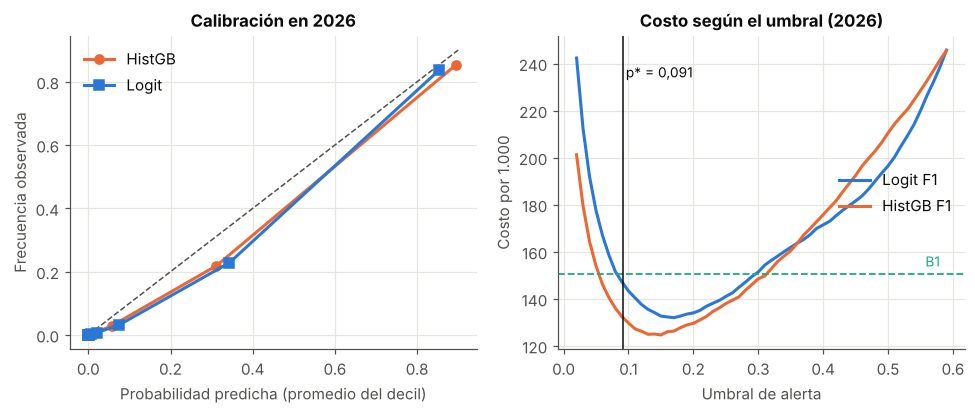

In [24]:
def ece(y, p, bins=10):
    q = pd.qcut(p, bins, duplicates="drop"); g = pd.DataFrame({"y": y, "p": p, "q": q}).groupby("q", observed=True).agg(y=("y", "mean"), p=("p", "mean"), n=("y", "size"))
    return float((abs(g.y - g.p) * g.n).sum() / g.n.sum()), g

e_h, cal_h = ece(yt, p_hg); e_l, cal_l = ece(yt, p_lg)
print(f"Probabilidad media predicha vs tasa real 2026 -> HistGB: {p_hg.mean():.3f}, Logit: {p_lg.mean():.3f}  vs  real: {yt.mean():.3f}")
print(f"Error de calibración esperado (ECE, 10 deciles): HistGB {e_h:.3f} · Logit {e_l:.3f}")
thr = np.round(np.arange(0.02, 0.60, 0.01), 2)
curve = {n: np.array([expected_cost(yt, PF[n] >= t) for t in thr]) for n in PF}
for n, c in curve.items():
    near = thr[c <= 1.02 * c.min()]; print(f"{n}: umbral óptimo empírico 2026 = {thr[c.argmin()]:.2f} (costo {c.min():.1f}) · rango dentro del 2%: {near.min():.2f}–{near.max():.2f} · costo en p* = {expected_cost(yt, PF[n] >= P_STAR):.1f} · p* dentro del rango: {near.min() <= P_STAR <= near.max()}")
thr_bt = float(best_thr["HistGB F1"])         # umbral óptimo de la etapa de diseño (2025): se conocía antes de abrir 2026
print(f"Política 'umbral por backtest del año anterior': umbral {thr_bt:.2f} (óptimo empírico en 2025) -> costo en 2026 = {expected_cost(yt, p_hg >= thr_bt):.1f} (con p* teórico: {expected_cost(yt, p_hg >= P_STAR):.1f})")
RES["backtest_thr"] = {"thr": thr_bt, "cost_2026": expected_cost(yt, p_hg >= thr_bt), "cost_pstar": expected_cost(yt, p_hg >= P_STAR)}
RES["calibration"] = {"mean_pred_hgb": float(p_hg.mean()), "mean_pred_logit": float(p_lg.mean()), "real": float(yt.mean()), "ece_hgb": e_h, "ece_logit": e_l}

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.7))
ax = axs[0]
ax.plot([0, 0.9], [0, 0.9], color=MUTED, lw=1, ls="--"); ax.plot(cal_h.p, cal_h.y, marker="o", color=ORANGE, lw=2, label="HistGB"); ax.plot(cal_l.p, cal_l.y, marker="s", color=BLUE, lw=2, label="Logit")
ax.set_xlabel("Probabilidad predicha (promedio del decil)"); ax.set_ylabel("Frecuencia observada"); ax.legend(); _ = ax.set_title("Calibración en 2026")
ax = axs[1]
for n, col in [("Logit F1", BLUE), ("HistGB F1", ORANGE)]: ax.plot(thr, curve[n], color=col, lw=2, label=n)
ax.axhline(expected_cost(yt, rows[kB1]), color=AQUA, ls="--", lw=1.2); ax.text(0.58, expected_cost(yt, rows[kB1]) + 3, "B1", color=AQUA, ha="right", fontsize=9)
ax.axvline(P_STAR, color=INK, lw=1); ax.text(P_STAR + 0.005, ax.get_ylim()[1] * 0.93, "p* = 0,091", fontsize=9)
ax.set_xlabel("Umbral de alerta"); ax.set_ylabel("Costo por 1.000"); ax.legend(loc="center right"); _ = ax.set_title("Costo según el umbral (2026)")

> **Lectura.** El modelo sigue sobreestimando la prevalencia (probabilidad media predicha 12,8% contra 11,1% reales; ECE 0,017), porque la tasa de quedar sin selección volvió a bajar. En 2026 el umbral teórico p\* = 0,091 queda **por debajo** del rango casi-óptimo de la curva empírica (0,12 a 0,17) y cuesta 132,2, unos 6% más que el óptimo posible a posteriori (≈ 124,6). Es decir, **la descalibración tiene un costo real, aunque moderado**.
>
> **Corrección propuesta (sin mirar 2026):** fijar el umbral con un *backtest* del año anterior. El óptimo empírico de la etapa de diseño (2025) fue 0,11; aplicado a 2026 da un costo de 127,3, mejor que con el umbral teórico. Así, la **regla de acción** recomendada es: alertar si `p ≥ umbral`, con el umbral reestimado cada año con el backtest del año recién cerrado, y p\* teórico como cota de referencia.

# 7. Componente no supervisado: sugerir alternativas por co-ocurrencia  *(T2.3)*
**¿Por qué una componente no supervisada?** La alerta por sí sola dice "tu lista es frágil", pero no *qué hacer*. Para sugerir alternativas hacen falta carreras **afines** a las que la persona ya eligió, y no hay etiquetas de "afinidad". Pero millones de listas reales sí revelan qué carreras elige junta la gente (aprendizaje no supervisado, sin etiqueta alguna).

**Método.**
1. Con las listas de **2024 y 2025** (años de entrenamiento) se cuenta cuántas veces dos carreras aparecen en la misma lista y se calcula la **similitud coseno** `sim(a,b) = co(a,b) / √(n_a · n_b)` (soporte mínimo 30 listas; 10 vecinas por carrera).
2. Para una persona alertada, se juntan las vecinas de cada carrera de su lista y se descartan las que ya tiene.
3. Para cada candidata se **calcula el puntaje ponderado que la persona tendría**, con los porcentajes de ponderación de la oferta 2026 (se valida que esta reconstrucción reproduce los puntajes reales), y se exige una holgura ≥ `m` puntos sobre el corte del año anterior (mismo margen que B1).
4. Se sugieren hasta 3 carreras: las de mayor similitud entre las que cumplen.

**Cómo se evalúa** (contrafactual aproximado, solo en 2026): entre las personas alertadas que efectivamente quedaron sin selección, ¿cuántas habrían sido seleccionadas en al menos una de las sugerencias con los cortes reales de 2026? Se compara contra sugerir carreras **al azar** que cumplan el mismo requisito de holgura (así se aísla el aporte de la co-ocurrencia).

In [25]:
def build_cooc(years, min_support=30, topk=10):
    L = pd.concat([post[y][(post[y].TIPO_PREF == "REGULAR") & (post[y].PTJE > 0)][["MRUN", "COD_CARRERA", "YEAR"]] for y in years]).drop_duplicates()
    uid = pd.factorize(L.YEAR.astype("int64") * 10**9 + L.MRUN.astype("int64"))[0]          # una "lista" = (postulante, año)
    careers, cidx = np.unique(L.COD_CARRERA.values, return_inverse=True)
    X = sparse.csr_matrix((np.ones(len(L)), (uid, cidx)), shape=(uid.max() + 1, len(careers)))
    co = (X.T @ X).tocsr(); n = co.diagonal(); rows = []
    for a in range(len(careers)):
        s, e = co.indptr[a], co.indptr[a + 1]; cols, vals = co.indices[s:e], co.data[s:e]
        m = (cols != a) & (vals >= min_support)
        if not m.any(): continue
        sim = vals[m] / np.sqrt(n[a] * n[cols[m]])
        for j in np.argsort(-sim)[:topk]: rows.append((careers[a], careers[cols[m][j]], sim[j]))
    return pd.DataFrame(rows, columns=["a", "b", "sim"])

TOPK = build_cooc([2024, 2025])
print(f"Carreras con vecinas: {TOPK.a.nunique():,} · pares: {len(TOPK):,} · similitud media {TOPK.sim.mean():.3f}")

# Oferta 2026: porcentajes de ponderación de cada carrera
of = pd.read_csv(DATA_ROOT / "2026" / "OFERTA_DEFINITIVA_PROGRAMAS_PAES_2026.csv", encoding="utf-8-sig").set_index("COD_CARRERA")
WC = ["NEM", "RANKING", "CLEC", "M1", "HSCO", "CIEN", "M2"]
wt = of[WC].fillna(0)
of["wsum"] = wt.NEM + wt.RANKING + wt.CLEC + wt.M1 + np.maximum(wt.HSCO, wt.CIEN) + wt.M2      # HSCO/CIEN ocupan un solo casillero
OK_CAR = set(of.index[of.wsum == 100])                                                           # el resto exige pruebas especiales: no se sugiere
SC = ["PTJE_NEM", "PTJE_RANKING", "CLEC_MAX", "MATE1_MAX", "MATE2_MAX", "HCSOC_MAX", "CIEN_MAX"]

def weighted_score(sc, w):
    a = lambda x: np.asarray(x, dtype=float)
    part = lambda wk, sk: np.where(a(wk) > 0, a(wk) * a(sk), 0.0)            # si el peso es 0 no importa que falte la prueba
    comp = part(w.NEM, sc.PTJE_NEM) + part(w.RANKING, sc.PTJE_RANKING) + part(w.CLEC, sc.CLEC_MAX) + part(w.M1, sc.MATE1_MAX) + part(w.M2, sc.MATE2_MAX)
    best = np.fmax(np.where(a(w.HSCO) > 0, a(sc.HCSOC_MAX), np.nan), np.where(a(w.CIEN) > 0, a(sc.CIEN_MAX), np.nan))
    slot = np.maximum(a(w.HSCO), a(w.CIEN))
    return (comp + np.where(slot > 0, slot * best, 0.0)) / 100                # NaN si falta una prueba exigida

# Validación de la reconstrucción: ¿reproduce el puntaje ponderado real de las preferencias que sí postularon?
r = post[2026][(post[2026].TIPO_PREF == "REGULAR") & (post[2026].PTJE > 0)]
r = r[r.COD_CARRERA.isin(OK_CAR)].sample(60_000, random_state=SEED).merge(cohort[2026][["MRUN"] + SC], on="MRUN")
err = np.abs(weighted_score(r[SC], wt.loc[r.COD_CARRERA]) - r.PTJE.values)
match = float(np.nanmean(err <= 0.1)); print(f"Reconstrucción del puntaje ponderado: {match*100:.2f}% de {len(r):,} preferencias reales con error ≤ 0,1 punto")
RES["weighted_score_match"] = match

Carreras con vecinas: 2,076 · pares: 19,733 · similitud media 0.245
Reconstrucción del puntaje ponderado: 99.76% de 60,000 preferencias reales con error ≤ 0,1 punto


In [26]:
SUG_MARGIN = max(m_f, 0.0)                         # mismo margen de seguridad que la regla B1
cut_prev26 = cuts[cuts.YEAR == 2025].set_index("COD_CARRERA").corte
cut_2026 = cuts[cuts.YEAR == 2026].set_index("COD_CARRERA").corte
lst26 = post[2026][(post[2026].TIPO_PREF == "REGULAR") & (post[2026].PTJE > 0)][["MRUN", "COD_CARRERA"]]

def finish(c, stu, k=3):
    c = c[c.b.isin(OK_CAR)].merge(stu[["MRUN"] + SC], on="MRUN")
    c["pond"] = weighted_score(c[SC], wt.loc[c.b]); c["holg"] = c.pond - c.b.map(cut_prev26)
    c = c[c.holg >= SUG_MARGIN].sort_values(["MRUN", "sim", "holg"], ascending=[True, False, False])
    c["rank"] = c.groupby("MRUN").cumcount(); return c[c["rank"] < k]

def drop_in_list(c, lst):
    c = c.merge(lst.rename(columns={"COD_CARRERA": "b"}).assign(inlist=1), on=["MRUN", "b"], how="left")
    return c[c.inlist.isna()].drop(columns="inlist")

alerted = TE.loc[p_hg >= P_STAR, ["MRUN", "y"] + SC].reset_index(drop=True)
lst = lst26[lst26.MRUN.isin(alerted.MRUN)]
# (a) co-ocurrencia
c = lst.merge(TOPK, left_on="COD_CARRERA", right_on="a").groupby(["MRUN", "b"], as_index=False).sim.max()
sg_co = finish(drop_in_list(c, lst), alerted)
# (b) azar: 15 carreras al azar por persona, con el mismo filtro de holgura
pool = np.array(sorted(OK_CAR)); rr = np.random.default_rng(SEED)
cr = pd.DataFrame({"MRUN": np.repeat(alerted.MRUN.values, 15), "b": rr.choice(pool, len(alerted) * 15)}); cr["sim"] = rr.random(len(cr))
sg_rd = finish(drop_in_list(cr.drop_duplicates(["MRUN", "b"]), lst), alerted)

# (c) comparador ingenuo: la misma carrera (mismo nombre) en otra universidad o sede, con el mismo filtro de holgura
import unicodedata
norm = lambda t: unicodedata.normalize("NFKD", str(t)).encode("ascii", "ignore").decode().upper()
names = of.CARRERA
nm_norm = names.map(norm); by_name = pd.DataFrame({"b": nm_norm.index, "nn": nm_norm.values})
cn = lst.assign(nn=lst.COD_CARRERA.map(nm_norm)).merge(by_name, on="nn")[["MRUN", "b"]].drop_duplicates(); cn["sim"] = rr.random(len(cn))
sg_nm = finish(drop_in_list(cn, lst), alerted)
area = lambda code_: nm_norm.reindex(code_).str.split().str[0].values                  # área aproximada = primera palabra del nombre
la = lst.assign(area=area(lst.COD_CARRERA))[["MRUN", "area"]].drop_duplicates().assign(same_area=1)
ln = lst.assign(name=lst.COD_CARRERA.map(nm_norm))[["MRUN", "name"]].drop_duplicates().assign(same=1)
def evaluate(sg, label):
    sg = sg.copy(); sg["ok26"] = sg.pond >= sg.b.map(cut_2026); sg["name"] = sg.b.map(nm_norm)
    sg = sg.merge(ln, on=["MRUN", "name"], how="left"); sg["area"] = area(sg.b); sg = sg.merge(la, on=["MRUN", "area"], how="left")
    per = sg.groupby("MRUN").agg(any_ok=("ok26", "any"))
    fell = alerted[alerted.y == 1].MRUN
    return {"método": label, "alertados con ≥1 sugerencia": alerted.MRUN.isin(sg.MRUN).mean(),
            "sugerencias por persona (media)": len(sg) / max(sg.MRUN.nunique(), 1),
            "sugerencias que habrían sido seleccionadas": sg.ok26.mean(),
            "personas que cayeron y habrían sido rescatadas": per.any_ok.reindex(fell).fillna(False).mean(),
            "pertinencia: mismo nombre que una de su lista": sg.same.notna().mean(),
            "pertinencia: misma área (1ª palabra del nombre)": sg.same_area.notna().mean()}
# (d) híbrido: primero el mismo nombre en otra universidad (más rescate) y, si faltan, las vecinas por co-ocurrencia (amplía opciones)
hy = pd.concat([sg_nm.assign(prio=0), sg_co.assign(prio=1)]).sort_values(["MRUN", "prio", "sim"], ascending=[True, True, False]).drop_duplicates(["MRUN", "b"])
hy["rank"] = hy.groupby("MRUN").cumcount(); sg_hy = hy[hy["rank"] < 3]
sub_tab = pd.DataFrame([evaluate(sg_co, "Co-ocurrencia (no supervisado)"), evaluate(sg_hy, "Híbrido: mismo nombre y luego co-ocurrencia"), evaluate(sg_nm, "Mismo nombre, otra universidad"), evaluate(sg_rd, "Al azar (mismo filtro de holgura)")]).set_index("método").T
display(sub_tab.round(3)); RES["substitutes"] = sub_tab.round(4).to_dict()
print(f"\nAlertados: {len(alerted):,} · de ellos que realmente quedaron sin selección: {int(alerted.y.sum()):,}")

método                                           Co-ocurrencia (no supervisado)  Híbrido: mismo nombre y luego co-ocurrencia  Mismo nombre, otra universidad  Al azar (mismo filtro de holgura)
alertados con ≥1 sugerencia                                               0.726                                        0.886                           0.795                              0.950
sugerencias por persona (media)                                           2.557                                        2.867                           2.834                              2.738
sugerencias que habrían sido seleccionadas                                0.958                                        0.971                           0.975                              0.947
personas que cayeron y habrían sido rescatadas                            0.615                                        0.807                           0.693                              0.937
pertinencia: mismo nombre que una de su 

> **Lectura (esta es una evaluación honesta, con resultado mixto).**
> - Se reconstruyó el puntaje ponderado con un error ≤ 0,1 punto en el 99,8% de las preferencias reales, así que los puntajes de las sugerencias son confiables.
> - **Al azar "gana" en rescate (94%) pero es una ilusión:** sugiere carreras sin relación con lo que la persona quiere (3% con el mismo nombre que alguna de su lista) que simplemente son fáciles de alcanzar. Por eso se mide también la **pertinencia**.
> - **La co-ocurrencia sola no supera al comparador ingenuo** "la misma carrera en otra universidad": cubre a menos personas (73% contra 80%) y rescata menos (61% contra 69%). Lo que aporta es **opciones distintas**: solo el 42% de sus sugerencias comparte el nombre de una carrera ya elegida, pero el 68% es de la misma área.
> - **El diseño híbrido es el que justifica la componente:** primero el mismo nombre y, si faltan, las vecinas por co-ocurrencia, sube la cobertura de 80% a **89%** y el rescate de 69% a **81%**, manteniendo una pertinencia alta (94% de la misma área). Con las limitaciones de la sección 11 (el contrafactual es optimista).

# 8. Explicabilidad  *(A2.1 y A2.2)*
Se usa un método **adecuado a cada familia de modelo**:
- **Regresión logística:** coeficientes estandarizados (cada coeficiente es el cambio en el *log-odds* de quedar sin selección por una desviación estándar de la variable). Permite además descomponer **una predicción individual** en contribuciones.
- **HistGradientBoosting:** *importancia por permutación* (cuánto empeora la log-loss en 2026 si se desordena una variable) y un gráfico observado-vs-predicho por tramos de la variable principal.

> **Importancia no es causalidad.** Estas técnicas dicen qué variables usa el modelo para *predecir*, no qué *causaría* quedar sin selección. Por ejemplo, tener muchas preferencias válidas se asocia con menor riesgo, pero eso no significa que agregar preferencias de cualquier tipo lo reduzca causalmente: las personas que arman listas más largas y más variadas también suelen informarse mejor.

Regresión logística — 10 coeficientes estandarizados más grandes:
 n_above_0         -2.384
best_holgura_p5   -1.773
best_holgura      -1.476
n_above_30        -0.670
mean_holgura      -0.512
n_above_60         0.509
ptje_oblig         0.502
gap_prev_best      0.421
best_ptje         -0.396
PTJE_NEM           0.375

HistGB — importancia por permutación (aumento de log-loss):
 best_holgura_p5     0.1676
best_holgura        0.0822
n_sin_corte_prev    0.0161
n_above_0           0.0113
ptje_oblig          0.0092
n_sel_prev_best     0.0054
gap_prev_best       0.0053
n_above_60          0.0048
mean_ptje           0.0046
cupo_pace           0.0027
            obs  pred      n
_bin                        
< −80      90.8  94.4   7608
−80 a −40  77.2  82.4   6458
−40 a 0    52.1  58.5  10556
0 a 40     11.2  17.5  17544
40 a 80     1.7   3.7  21318
80 a 120    0.5   1.3  22622
> 120       0.1   0.2  95201


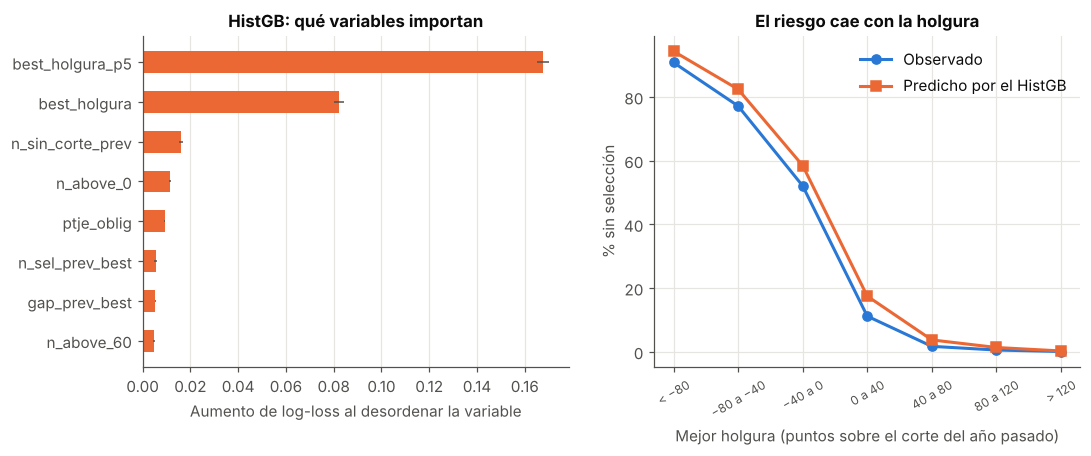

In [27]:
nm = lg.named_steps["pre"].get_feature_names_out(); coef = pd.Series(lg.named_steps["clf"].coef_[0], index=[n.replace("num__", "").replace("missingindicator_", "falta_") for n in nm])
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)
print("Regresión logística — 10 coeficientes estandarizados más grandes:\n", top.round(3).to_string())

samp = TE.sample(25_000, random_state=SEED)
pi = permutation_importance(hg_models[0], samp[F1], samp.y, scoring="neg_log_loss", n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=F1).sort_values(ascending=False)
imp_sd = pd.Series(pi.importances_std, index=F1).reindex(imp.index)
print("\nHistGB — importancia por permutación (aumento de log-loss):\n", imp.head(10).round(4).to_string())
RES["importance_hgb"] = imp.head(10).round(5).to_dict()

fig, axs = plt.subplots(1, 2, figsize=(11, 3.9))
ax = axs[0]; t = imp.head(8)[::-1]
ax.barh(t.index, t.values, xerr=imp_sd.reindex(t.index).values, color=ORANGE, height=0.55, error_kw={"lw": 1, "ecolor": MUTED}); ax.grid(axis="y", visible=False)
ax.set_xlabel("Aumento de log-loss al desordenar la variable"); _ = ax.set_title("HistGB: qué variables importan")
ax = axs[1]
bins = [-np.inf, -80, -40, 0, 40, 80, 120, np.inf]; lab_b = ["< −80", "−80 a −40", "−40 a 0", "0 a 40", "40 a 80", "80 a 120", "> 120"]
TE["_bin"] = pd.cut(TE.best_holgura, bins, labels=lab_b); TE["p_hg"] = p_hg
g = TE.groupby("_bin", observed=True).agg(obs=("y", "mean"), pred=("p_hg", "mean"), n=("y", "size"))
ax.plot(range(len(g)), g.obs * 100, marker="o", color=BLUE, lw=2, label="Observado"); ax.plot(range(len(g)), g.pred * 100, marker="s", color=ORANGE, lw=2, label="Predicho por el HistGB")
ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index, rotation=30, fontsize=8); ax.set_xlabel("Mejor holgura (puntos sobre el corte del año pasado)"); ax.set_ylabel("% sin selección")
ax.legend(); _ = ax.set_title("El riesgo cae con la holgura")
display(g.assign(obs=lambda d: (d.obs * 100).round(1), pred=lambda d: (d.pred * 100).round(1)))

> **Lectura.**
> - **Qué variables determinan las predicciones.** Con ambos métodos manda lo mismo: **qué tan por encima de los cortes del año anterior están las mejores opciones de la lista.** En el HistGB, las dos variables de holgura (`best_holgura_p5`: 0,168 y `best_holgura`: 0,082 de aumento de log-loss al desordenarlas) pesan, de lejos, más que todo lo demás (la tercera, `n_sin_corte_prev`, apenas 0,016). La holgura medida contra el **percentil 5** de los seleccionados, más robusto que el mínimo, pesa más que la holgura contra el mínimo.
> - **El riesgo cae de forma monótona con la holgura:** ≈ 91% de quedar sin selección cuando la mejor opción está más de 80 puntos bajo el corte, ≈ 52% entre −40 y 0, ≈ 11% entre 0 y 40 y menos de 2% sobre 40. El modelo sobreestima el riesgo en los tramos intermedios (por ejemplo 17,5% predicho contra 11,2% observado entre 0 y 40), coherente con la caída de la prevalencia.
> - **Cuidado con los coeficientes del logit:** las variables de holgura están muy correlacionadas entre sí (por eso `n_above_60` sale con signo positivo aunque su efecto marginal conjunto es protector). Sirven para ordenar la importancia, **no** para interpretar cada coeficiente por separado.
> - **Importancia no es causalidad.** El modelo dice que listas sin opciones sobre el corte suelen quedar sin selección; no dice que *subir artificialmente* la holgura cambie el resultado de alguien. Y como los cortes cambian de año en año (≈ 50 puntos), una holgura positiva **no garantiza** selección.

## 8.1 Predicciones individuales  *(A2.2)*
Se eligen tres casos de 2026, **por regla y no a mano**: una alerta correcta (persona alertada que quedó sin selección, con probabilidad cercana a 0,5), una falsa alarma (alertada pero seleccionada, probabilidad cercana a 0,3) y una falla del modelo (no alertada y sin selección, con la probabilidad mediana entre las fallas). Para cada uno: su lista, la probabilidad, las contribuciones del modelo logístico y las sugerencias.

In [28]:
TE["alert"] = p_hg >= P_STAR
def pick(mask, target):
    idx = np.where(mask)[0]; return int(idx[np.argmin(np.abs(p_hg[idx] - target))])
iA = pick(TE.alert.values & (yt == 1), 0.5); iB = pick(TE.alert.values & (yt == 0), 0.3)
fn_idx = np.where(~TE.alert.values & (yt == 1))[0]; iC = int(fn_idx[np.argsort(p_hg[fn_idx])[len(fn_idx) // 2]])
Xs = lg.named_steps["pre"].transform(TE[F1]); coef_all = lg.named_steps["clf"].coef_[0]

def show_case(i, titulo):
    mrun = int(TE.MRUN.iloc[i]); print("=" * 100); print(f"{titulo}  (MRUN {mrun})  ·  y real = {int(yt[i])}  ·  p(HistGB) = {p_hg[i]:.3f}  ·  p(logit) = {p_lg[i]:.3f}  ·  alerta = {bool(TE.alert.iloc[i])}")
    pr = post[2026][(post[2026].MRUN == mrun) & (post[2026].TIPO_PREF == "REGULAR")].sort_values("ORDEN_PREF").copy()
    pr["carrera"] = pr.COD_CARRERA.map(of.CARRERA).fillna("(carrera sin datos)").str.title().str[:34]; pr["universidad"] = pr.COD_CARRERA.map(of.UNIVERSIDAD).fillna("").str.title().str[:28]
    pr["corte 2025"] = pr.COD_CARRERA.map(cut_prev26); pr["holgura"] = (pr.PTJE - pr["corte 2025"]).round(1)
    pr["corte 2026 (ex post)"] = pr.COD_CARRERA.map(cut_2026)                   # solo para explicar el caso a posteriori; el modelo NO lo ve
    gan = post[2026][(post[2026].MRUN == mrun) & (post[2026].ESTADO == 24)]
    show = pd.concat([pr.head(6), pr[pr.COD_CARRERA.isin(gan.COD_CARRERA)]]).drop_duplicates(["ORDEN_PREF"])      # primeras 6 + donde fue seleccionado/a
    print(f"(lista completa: {len(pr)} preferencias; se muestran las primeras 6 y la preferencia ganadora)")
    print(show[["ORDEN_PREF", "carrera", "universidad", "PTJE", "corte 2025", "holgura", "corte 2026 (ex post)"]].rename(columns={"PTJE": "puntaje"}).to_string(index=False))
    print("Resultado real:", "; ".join(f"seleccionado/a en {of.CARRERA.get(a, '?').title()} ({t})" for a, t in zip(gan.COD_CARRERA, gan.TIPO_PREF)) if len(gan) else "no fue seleccionado/a en ninguna preferencia")
    contrib = pd.Series(Xs[i] * coef_all, index=coef.index).sort_values()
    print("Lo que más empuja HACIA más riesgo (logit):", ", ".join(f"{k} ({v:+.2f})" for k, v in contrib.tail(3)[::-1].items()))
    print("Lo que más empuja HACIA menos riesgo (logit):", ", ".join(f"{k} ({v:+.2f})" for k, v in contrib.head(3).items()))
    s = sg_co[sg_co.MRUN == mrun]
    if len(s): print("Sugerencias:\n" + "\n".join(f"   · {of.CARRERA[b].title()} — {of.UNIVERSIDAD[b].title()}  (tu puntaje ponderado sería {pn:.1f}; corte 2025 {cut_prev26[b]:.1f})" for b, pn in zip(s.b, s.pond)))
    elif bool(TE.alert.iloc[i]): print("Sugerencias: ninguna cumple el requisito de holgura")
show_case(iA, "CASO A · alerta correcta"); show_case(iB, "CASO B · falsa alarma"); show_case(iC, "CASO C · falla (sin alerta, quedó sin selección)")

CASO A · alerta correcta  (MRUN 1812155)  ·  y real = 1  ·  p(HistGB) = 0.500  ·  p(logit) = 0.368  ·  alerta = True
(lista completa: 1 preferencias; se muestran las primeras 6 y la preferencia ganadora)
 ORDEN_PREF                  carrera              universidad  puntaje  corte 2025  holgura  corte 2026 (ex post)
          1 Contabilidad Y Auditoría Universidad De O'Higgins    536.5       549.6    -13.1                 599.3
Resultado real: no fue seleccionado/a en ninguna preferencia
Lo que más empuja HACIA más riesgo (logit): n_above_0 (+2.53), best_holgura_p5 (+1.89), best_holgura (+1.55)
Lo que más empuja HACIA menos riesgo (logit): PTJE_NEM (-0.61), n_above_60 (-0.42), cupo_pace (-0.38)
Sugerencias: ninguna cumple el requisito de holgura
CASO B · falsa alarma  (MRUN 18820755)  ·  y real = 0  ·  p(HistGB) = 0.300  ·  p(logit) = 0.515  ·  alerta = True
(lista completa: 10 preferencias; se muestran las primeras 6 y la preferencia ganadora)
 ORDEN_PREF           carrera            

> **Qué se comunicaría a cada persona** (la alerta es un aviso, no un veredicto; siempre con revisión humana). *Los casos se eligen por regla y semilla; si se re-ejecuta en otra máquina pueden cambiar levemente.*
> - **Caso A (alerta correcta):** lista de una sola carrera con puntaje 536,5 contra un corte de 549,6 el año pasado: la alerta es acertada (el corte de 2026 subió a 599,3 y quedó sin selección). El mensaje: *"Tu lista tiene una sola opción y está 13 puntos bajo el corte del año pasado. Agrega opciones donde tu puntaje esté claramente sobre el corte."* En este caso el sistema **no pudo sugerir ninguna carrera** que cumpliera el margen de seguridad: la alerta debe derivar entonces a orientación humana, no quedarse en la advertencia.
> - **Caso B (falsa alarma):** su mejor opción estaba 6 puntos bajo el corte del año pasado y el modelo asignó 0,30; sin embargo, quedó seleccionada en Psicología (Santo Tomás): el corte de esa carrera **bajó** de 596 a 567 en 2026. Es la cara opuesta de la incertidumbre de los cortes. El mensaje debe ser probabilístico (*"tu lista tiene riesgo alto"*), no categórico (*"no vas a quedar"*).
> - **Caso C (falla del modelo):** su mejor opción tenía 34 puntos de holgura (justo bajo el margen de 35) y sus dos únicas opciones con holgura positiva (34 y 54 puntos) fallaron porque los cortes de 2026 **subieron** 47 y 98 puntos. El modelo, con probabilidad 0,05, no alertó. Muestra el límite de cualquier sistema basado en los cortes del año anterior.

# 9. Subgrupos y equidad  *(A2.3)*
El modelo **no usa** sexo, región ni variables socioeconómicas (el modelo F2, que sí las usaba, no mejoraba y se descartó). Aun así puede comportarse distinto por grupo, porque variables como el puntaje o el tipo de lista pueden ser *proxies* de esas características. Se audita con el modelo final y se compara con B1.

Para cada grupo: la **tasa real** de quedar sin selección, la **tasa de alerta**, el **recall** (de quienes quedaron sin selección, ¿a cuántos se les avisó?), la **precisión** y el costo por 1.000.

In [29]:
TE["alert_b1"] = rule_alert(TE, m_f); TE["alert_b0"] = rule_alert(TE, 0)
dep_map = {1: "Municipal / SLE", 2: "Municipal / SLE", 6: "Municipal / SLE", 3: "Particular subvencionado", 4: "Particular pagado", 5: "Admin. delegada"}
cupo = np.select([TE.cupo_pace == 1, TE.cupo_bea == 1, TE.cupo_genero == 1], ["Postula a cupo PACE", "Postula a cupo BEA", "Postula a cupo de género"], "Solo cupo regular")
GR = {"Sexo": TE.sexo.map({1: "Hombre", 2: "Mujer"}).fillna("s/d"),
      "Ingreso per cápita": pd.cut(TE.ingreso_decil, [0, 3, 6, 10], labels=["Deciles 1–3", "Deciles 4–6", "Deciles 7–10"]).astype(object).fillna("Sin dato"),
      "Dependencia": TE.DEPENDENCIA.map(dep_map).fillna("s/d"), "Rama": np.where(TE.is_tp == 1, "Técnico-profesional", "Humanista-científica"),
      "Región": np.where(TE.region == 13, "Metropolitana", "Otras regiones"), "Cupos": cupo,
      "Carrera nueva en la lista": np.where(TE.n_sin_corte_prev > 0, "Con carrera sin corte previo", "Todas con corte previo")}
GR = {g: (v if isinstance(v, pd.Series) else pd.Series(np.asarray(v), index=TE.index)) for g, v in GR.items()}
has_sug = TE.MRUN.isin(sg_hy.MRUN).values
def grp_metrics(mask):
    y_, a_, b_ = yt[mask], TE.alert.values[mask], TE.alert_b1.values[mask]
    return {"n": int(mask.sum()), "tasa real": y_.mean(), "tasa de alerta": a_.mean(), "recall": (a_ & (y_ == 1)).sum() / max((y_ == 1).sum(), 1),
            "precisión": (a_ & (y_ == 1)).sum() / max(a_.sum(), 1), "recall B1": (b_ & (y_ == 1)).sum() / max((y_ == 1).sum(), 1),
            "costo/1000 modelo": expected_cost(y_, a_), "costo/1000 B1": expected_cost(y_, b_), "p media predicha": p_hg[mask].mean(),
            "% alertados con sugerencia": has_sug[mask & TE.alert.values].mean() if (mask & TE.alert.values).any() else np.nan}
sub = pd.concat({g: pd.DataFrame({k: grp_metrics((s == k).values) for k in sorted(s.unique())}).T for g, s in GR.items()})
display(sub.round(3))
RES["subgroups"] = {f"{a} | {b}": r.round(4).to_dict() for (a, b), r in sub.iterrows()}

                                                               n  tasa real  tasa de alerta  recall  precisión  recall B1  costo/1000 modelo  costo/1000 B1  p media predicha  % alertados con sugerencia
Sexo                      Hombre                         78398.0      0.104           0.199   0.960      0.503      0.940            139.812        160.310             0.113                       0.902
                          Mujer                         103640.0      0.116           0.229   0.989      0.500      0.986            126.428        143.545             0.139                       0.877
Ingreso per cápita        Deciles 1–3                    54355.0      0.114           0.225   0.979      0.498      0.970            136.970        155.367             0.132                       0.888
                          Deciles 4–6                    32295.0      0.106           0.211   0.978      0.491      0.971            130.547        145.998             0.124                   

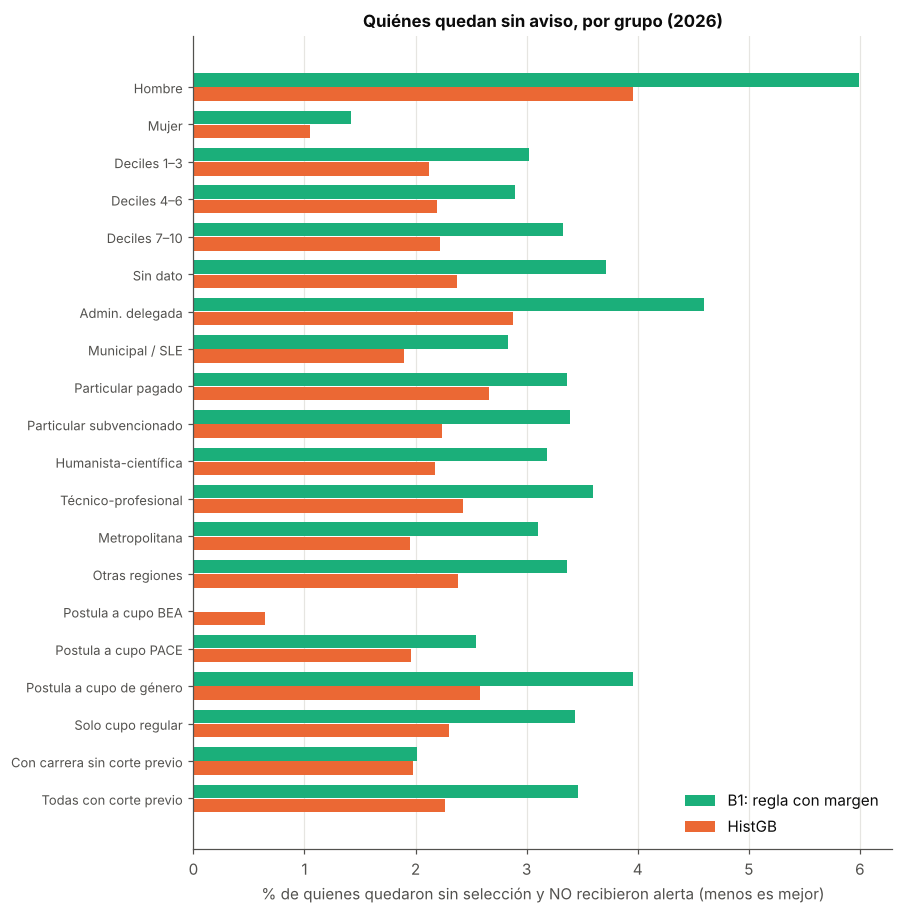

In [30]:
# Gráfico: de quienes quedaron sin selección, ¿a qué fracción NO se le avisó? (menos es mejor) — modelo vs. B1
sel = sub[sub.n >= 800].copy(); sel = sel.drop(index=[i for i in sel.index if i[1] == "s/d"], errors="ignore")
lab_g = [f"{b}" for a, b in sel.index]
fig, ax = plt.subplots(figsize=(8.2, 0.42 * len(sel) + 1.2)); yy = np.arange(len(sel))[::-1]
ax.barh(yy + 0.19, (1 - sel["recall B1"]) * 100, height=0.36, color=AQUA, label="B1: regla con margen"); ax.barh(yy - 0.19, (1 - sel["recall"]) * 100, height=0.36, color=ORANGE, label="HistGB")
ax.set_yticks(yy); ax.set_yticklabels(lab_g, fontsize=8.5); ax.set_xlabel("% de quienes quedaron sin selección y NO recibieron alerta (menos es mejor)"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right"); _ = ax.set_title("Quiénes quedan sin aviso, por grupo (2026)")

> **Lectura (equidad, comparando el modelo con B1).**
> - **Recall casi parejo.** Entre quienes quedan sin selección, se le avisa al 98% del primer tramo de ingreso y al 98% del más alto; al 98% de la rama técnico-profesional y al 98% de la humanista; al 98% fuera de la Región Metropolitana y al 98% dentro. La diferencia más grande es por **sexo: se avisa al 99,0% de las mujeres y al 96,0% de los hombres** (la regla B1 tiene una brecha parecida: 98,6% vs 94,0%). La precisión es igual en ambos (50% y 50%), así que la brecha no viene de más falsas alarmas. Sí se observa que el modelo **sobreestima más el riesgo de las mujeres** (predice 13,9% contra 11,6% reales; en los hombres 11,3% contra 10,4%) y por eso les alerta más (23% vs 20%). **No alcanzamos a investigar el origen de esta diferencia** y se declara como limitación; el sexo no es una variable del modelo.
> - **La carga de falsas alarmas sí es desigual.** La tasa de alerta es 27% en técnico-profesional contra 20% en humanista, 24% en colegios municipales contra 15% en particulares pagados, y 24% fuera de la RM contra 18% en ella. Es consistente con que la tasa real de fallar también es mayor en esos grupos (por ejemplo 13,8% vs 10,5%), y la precisión es algo menor (48% fuera de la RM vs 54%): los grupos con mayor tasa de falla reciben más alertas y una proporción algo mayor de ellas no se cumple.
> - **Proxies.** Sin usar ingreso ni dependencia, el modelo igual da probabilidades medias más altas a quienes tienen menos ingreso (13,2% en el decil 1–3 vs 11,8% en 7–10) porque los puntajes y el tipo de lista actúan como proxies de esas características. Eso es esperable (esas personas efectivamente fallan más) pero obliga a vigilar que la alerta se use para **ayudar** y no para filtrar ni para decidir sobre ellas.
> - **La ayuda llega parejo:** el 89% de los alertados del primer tramo de ingreso recibe al menos una sugerencia, contra 89% del tramo más alto. Donde el sistema cubre peor es en postulantes a cupo BEA (60%).
> - **Carreras nuevas:** si la lista incluye una carrera sin corte previo, el modelo avisa a igual proporción de quienes fallan (recall 98%), pero con muchas más falsas alarmas (precisión 39% vs 52%).

# 10. Riesgos operativos y monitoreo  *(A3.1)*
Para detectar que el modelo dejó de ser válido se proponen señales simples, calculables **antes de conocer los resultados**:
1. **Cambio en la distribución de las variables** (PSI, *population stability index*): compara la distribución de cada variable del año nuevo con la del año anterior. Regla práctica: PSI < 0,1 estable; 0,1–0,25 vigilar; > 0,25 re-entrenar.
2. **Tasa de alertas vs. la esperada:** si la proporción de alertas se aleja mucho de la del año anterior, algo cambió (por ejemplo, la oferta o el sistema de cortes).
3. **Cobertura de cortes previos:** porcentaje de preferencias en carreras sin corte del año anterior (carreras nuevas); si crece, la variable principal pierde información.

In [31]:
def psi(a, b, bins=10):
    a, b = a.dropna(), b.dropna(); qs = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1))); qs[0], qs[-1] = -np.inf, np.inf
    pa = np.histogram(a, qs)[0] / len(a) + 1e-6; pb = np.histogram(b, qs)[0] / len(b) + 1e-6
    return float(((pb - pa) * np.log(pb / pa)).sum())
mon = []
for f in ["best_holgura", "best_ptje", "n_prefs", "n_valid", "mean_holgura", "n_sin_corte_prev"]:
    mon.append({"variable": f, "PSI 2024→2025": psi(cohort[2024][f], cohort[2025][f]), "PSI 2025→2026": psi(cohort[2025][f], cohort[2026][f])})
mon = pd.DataFrame(mon).set_index("variable"); display(mon.round(3))
cov = pd.DataFrame({y: {"% preferencias en carreras sin corte previo": 1 - post[y][(post[y].TIPO_PREF == "REGULAR") & (post[y].PTJE > 0)].COD_CARRERA.isin(cuts[cuts.YEAR == y - 1].COD_CARRERA).mean(),
                        "tasa de alerta de la regla B1": rule_alert(cohort[y][cohort[y].efectivo == 1], m_f).mean()} for y in [2024, 2025, 2026]}).T
display(cov.round(4)); RES["monitoring"] = {"psi": mon.round(4).to_dict(orient="index"), "coverage": cov.round(4).to_dict(orient="index")}

                  PSI 2024→2025  PSI 2025→2026
variable                                      
best_holgura              0.001          0.008
best_ptje                 0.001          0.003
n_prefs                   0.002          0.003
n_valid                   0.002          0.003
mean_holgura              0.001          0.009
n_sin_corte_prev          0.000          0.005
      % preferencias en carreras sin corte previo  tasa de alerta de la regla B1
2024                                       0.0234                         0.2585
2025                                       0.0218                         0.2498
2026                                       0.0316                         0.2215


> **Lectura (y una advertencia).** Todas las variables de entrada se mantuvieron **estables** (PSI ≤ 0,009, muy por debajo de 0,1), **y sin embargo la tasa de quedar sin selección cayó de 13,6% a 11,1% entre 2025 y 2026**. Es decir, **el monitoreo de las entradas no habría detectado el cambio importante**: estaba en la relación entre variables y resultado. Por eso se recomienda monitorear además (i) la **calibración anual** (probabilidad media predicha vs tasa observada, cuando cierra el proceso), (ii) la **tasa de alertas** (la de la regla B1 bajó de 26% a 22% en dos años) y (iii) la **cobertura de cortes previos**, que subió de 2,2% a 3,2%.

# 11. Lo que probamos y no funcionó, lo que no alcanzamos a verificar y lo que nos sorprendió  *(T4.3)*

**Probado y descartado**
- **Corrección de prevalencia con EM:** no recuperó la caída de la tasa (estimó ≈ 15% cuando la real fue 13,6%) y casi no cambió el costo; se descartó.
- **Variables socioeducativas (F2):** no mejoraron el costo (incluso lo empeoraron levemente en el diseño). Se dejaron fuera.
- **Regresión logística como modelo propuesto:** su ventaja sobre la regla simple con margen (B1) es pequeña (≈ −4 puntos de costo en 2026 y no distinguible en 2025); se conserva como modelo interpretable y de contraste.
- **Sugerencias solo por co-ocurrencia:** no superan a la simple regla "la misma carrera en otra universidad" ni en cobertura ni en rescate; su aporte es ampliar opciones (sección 7), por eso se propone un diseño híbrido.
- **Umbral teórico p\* sin ajuste:** en 2026 queda por debajo del óptimo empírico y cuesta ≈ 6% más; se propone fijar el umbral con un backtest del año anterior.

**No alcanzamos a verificar**
- **La lista vigente al momento de la alerta.** Las bases solo traen la lista **final** de cada persona; la alerta real se emitiría con listas parciales que todavía pueden cambiar hasta el cierre. El desempeño real podría ser distinto.
- **El efecto de la alerta.** No sabemos cuántas personas alertadas cambiarían su lista, ni si eso las llevaría a ser seleccionadas. Se necesita un **piloto** con grupo de comparación.
- **Capacidad real de las carreras sugeridas.** El contrafactual usa los cortes reales de 2026 como si la persona hubiera sumado una postulación sin alterarlos; si muchas personas fueran dirigidas a las mismas carreras, esos cortes subirían.
- **Años anteriores a 2023** (proceso PDT) y años posteriores a 2026.
- **El valor del costo 10:1** (supuesto de negocio): se hizo sensibilidad, no calibración con datos de costos reales.
- **Reversión del corte** (`delta_prev_best`): su evaluación temporal usa un solo par de años.

**Resultados que nos sorprendieron**
- Que una regla simple con un margen de ≈ 35 a 40 puntos recupere entre 60% (2026) y 80% (2025) de lo que el ML mejora sobre la regla de hoy: **comparar contra un baseline "ingenuo" habría exagerado el valor del ML**.
- Que entrenar **solo con el año más reciente** (2025) haya dado mejor costo en 2026 (127) que entrenar con 2024+2025 (132): los datos antiguos parecen restar. Es una observación *posterior* a la evaluación (no una decisión pre-registrada) que debe confirmarse con el siguiente año.
- Que el monitoreo de las **entradas** (PSI) no detecte nada (todo estable, PSI < 0,01) mientras la tasa de resultado caía de 13,6% a 11,1%: el cambio relevante estaba en el resultado, no en las variables.
- La **caída sostenida** de la tasa de quedar sin selección (23,5% → 14,5%) en solo cuatro años.
- Que la correlación negativa entre cambios sucesivos de cortes (reversión) sea tan débil y solo clara en un par de años, y que aun así la variable de reversión sea una de las pocas que aporta señal en la validación cruzada dentro de 2025.
- Que las variables socioeducativas no agreguen información una vez conocidos los puntajes y la lista.

# 12. Reproducibilidad y cierre  *(T3.1 a T3.3)*
- **Incertidumbre:** bootstrap pareado de 300 remuestras (diferencias de costo entre métodos con IC95%), 5 semillas para el HistGB y dos evaluaciones temporales independientes (diseño 2024 → 2025 y final 2024+2025 → 2026) con resultados consistentes.
- **Semillas:** `SEED = 42` en la búsqueda de hiperparámetros, los modelos, las muestras y los bootstraps.
- **Sin fuga de datos:** variables y cortes previos al cierre; hiperparámetros y margen solo con CV interna; 2026 usado una sola vez; `ESTADO_PREF` jamás como variable; alarma de AUC investigada con prueba placebo.
- **Datos:** los .csv públicos originales en `data/raw/<año>/` (descarga desde la página de datos abiertos de DEMRE/Mineduc); en 2026 también la `base_no_seleccionados.csv` del módulo 1 para verificar la etiqueta.

In [32]:
# Salidas para el Análisis de la Solución (PDF) y para reutilizar
RES["final"] = final.round(4).to_dict(orient="index"); RES["final_boot"] = {k: {"media": float(v.mean()), "ic": [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))]} for k, v in cmp_final.items()}
RES["params"] = {"margin_B1": m_f, "C_logit": C_f, "hgb": hgb_f, "p_star": P_STAR, "n_test_efectivos": int(len(TE)), "n_test_sin_preferencia_valida": int(n_inv), "n_test_positivos": int(yt.sum())}
RES["hgb_seeds_cost"] = [round(expected_cost(yt, p >= P_STAR), 2) for p in p_hg_all]
pd.DataFrame({"MRUN": TE.MRUN, "y_real": yt, "p_histgb": p_hg.round(5), "alerta": TE.alert.astype(int)}).to_csv(OUT / "predicciones_2026.csv", index=False)
json.dump(RES, open(OUT / "metrics.json", "w"), ensure_ascii=False, indent=1, default=float)
print(f"Guardado results/metrics.json y results/predicciones_2026.csv · tiempo total del notebook: {(time.time()-t_start)/60:.1f} min")

Guardado results/metrics.json y results/predicciones_2026.csv · tiempo total del notebook: 7.1 min


### Declaración de uso de IA
Se utilizó **Claude (Anthropic)** como asistente para estructurar el análisis, escribir y depurar el código y redactar el texto base de este informe. Las decisiones de diseño se discutieron en el equipo y los resultados provienen de la ejecución de este notebook sobre las bases públicas. *(El equipo debe revisar y ajustar esta declaración a lo que efectivamente hizo y verificó cada integrante antes de entregar.)*